# Nieparametryczna analiza czynników wpływających na wyniki w nauce i modelowanie predykcyjne z wykorzystaniem uczenia maszynowego

* `Hours_Studied` - liczba godzin spędzanych tygodniowo na naukę,
* `Attendance` - frekwencja na lekcjach (%),
* `Parental_Involvement` - poziom zaangażowania rodziców w edukację ucznia,
* `Access_to_Resources`- dostępność edukacyjnych zasobów,
* `Extracurricular_Activities` - uczęszczanie na dodatkowe zajęcia,
* `Sleep_Hours`	- średnia liczba godzin snu,
* `Previous_Scores`	- wyniki z poprzednich egzaminów,
* `Motivation_Level`	- poziom motywacji,
* `Internet_Access`	- dostępność internetu,
* `Tutoring_Sessions` - liczba korepetycji w miesiącu,
* `Family_Income`	- poziom dochodu rodziny,
* `Teacher_Quality`	- jakość nauczycieli,
* `School_Type` - rodzaj szkoły,
* `Peer_Influence`	- wpływ równieśników na edukację,
* `Physical_Activity`	- średnia liczba godzin poświęcanych na aktywność fizyczną w tygodniu,
* `Learning_Disabilities`	- trudności w nauce,
* `Parental_Education_Level`	- najwyższy typ wykształcenia rodziców,
* `Distance_from_Home`	- odległość od domu,
* `Gender`	- płeć,
* `Exam_Score`	- wynik egzaminu końcowego.

Celem projektu jest **identyfikacja czynników związanych z wynikami w nauce** oraz stworzenie **modelu prognozującego wyniki w nauce na podstawie danych behawioralnych, środowiskowych oraz nawyków edukacyjnych uczniów.**

## 1. Przygotowanie i czyszczenie danych

### 1.1. Import bibliotek

In [1]:
#pbsługa danych
import numpy as np
import pandas as pd

#wizualizacja
import matplotlib.pyplot as plt
import pylab as py
import seaborn as sns

#testy statystyczne
import scikit_posthocs as sp
from scipy import stats
import statsmodels.api as sm

#imputacja danych
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer

#modele uczenia maszynowego
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import RandomizedSearchCV, train_test_split

### 1.2. Wczytywanie danych

In [2]:
dane = pd.read_csv('StudentPerformanceFactors.csv')

In [3]:
dane

,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
0,23,84,Low,High,No,7,73,Low,Yes,0,Low,Medium,Public,Positive,3,No,High School,Near,Male,67
1,19,64,Low,Medium,No,8,59,Low,Yes,2,Medium,Medium,Public,Negative,4,No,College,Moderate,Female,61
2,24,98,Medium,Medium,Yes,7,91,Medium,Yes,2,Medium,Medium,Public,Neutral,4,No,Postgraduate,Near,Male,74
3,29,89,Low,Medium,Yes,8,98,Medium,Yes,1,Medium,Medium,Public,Negative,4,No,High School,Moderate,Male,71
4,19,92,Medium,Medium,Yes,6,65,Medium,Yes,3,Medium,High,Public,Neutral,4,No,College,Near,Female,70
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6602,25,69,High,Medium,No,7,76,Medium,Yes,1,High,Medium,Public,Positive,2,No,High School,Near,Female,68
6603,23,76,High,Medium,No,8,81,Medium,Yes,3,Low,High,Public,Positive,2,No,High School,Near,Female,69
6604,20,90,Medium,Low,Yes,6,65,Low,Yes,3,Low,Medium,Public,Negative,2,No,Postgraduate,Near,Female,68
6605,10,86,High,High,Yes,6,91,High,Yes,2,Low,Medium,Private,Positive,3,No,High School,Far,Female,68


### 1.3. Informacje o danych

In [4]:
dane.info()

<class 'pandas.DataFrame'>
RangeIndex: 6607 entries, 0 to 6606
Data columns (total 20 columns):
 #   Column                      Non-Null Count  Dtype
---  ------                      --------------  -----
 0   Hours_Studied               6607 non-null   int64
 1   Attendance                  6607 non-null   int64
 2   Parental_Involvement        6607 non-null   str  
 3   Access_to_Resources         6607 non-null   str  
 4   Extracurricular_Activities  6607 non-null   str  
 5   Sleep_Hours                 6607 non-null   int64
 6   Previous_Scores             6607 non-null   int64
 7   Motivation_Level            6607 non-null   str  
 8   Internet_Access             6607 non-null   str  
 9   Tutoring_Sessions           6607 non-null   int64
 10  Family_Income               6607 non-null   str  
 11  Teacher_Quality             6529 non-null   str  
 12  School_Type                 6607 non-null   str  
 13  Peer_Influence              6607 non-null   str  
 14  Physical_Activity  

In [5]:
unique = dane.drop(columns=['Exam_Score', 'Previous_Scores','Sleep_Hours', 'Attendance', 'Hours_Studied'], errors='ignore').columns 

for col in unique:
    print(f"Zmienna {col} przyjmuje wartości: {dane[col].unique().tolist()}")

Zmienna Parental_Involvement przyjmuje wartości: ['Low', 'Medium', 'High']
Zmienna Access_to_Resources przyjmuje wartości: ['High', 'Medium', 'Low']
Zmienna Extracurricular_Activities przyjmuje wartości: ['No', 'Yes']
Zmienna Motivation_Level przyjmuje wartości: ['Low', 'Medium', 'High']
Zmienna Internet_Access przyjmuje wartości: ['Yes', 'No']
Zmienna Tutoring_Sessions przyjmuje wartości: [0, 2, 1, 3, 4, 5, 6, 7, 8]
Zmienna Family_Income przyjmuje wartości: ['Low', 'Medium', 'High']
Zmienna Teacher_Quality przyjmuje wartości: ['Medium', 'High', 'Low', nan]
Zmienna School_Type przyjmuje wartości: ['Public', 'Private']
Zmienna Peer_Influence przyjmuje wartości: ['Positive', 'Negative', 'Neutral']
Zmienna Physical_Activity przyjmuje wartości: [3, 4, 2, 1, 5, 0, 6]
Zmienna Learning_Disabilities przyjmuje wartości: ['No', 'Yes']
Zmienna Parental_Education_Level przyjmuje wartości: ['High School', 'College', 'Postgraduate', nan]
Zmienna Distance_from_Home przyjmuje wartości: ['Near', 'Moder

In [7]:
kategoryczne = [
    'Teacher_Quality',
    'Parental_Education_Level',
    'Distance_from_Home',
    'Parental_Involvement',
    'Access_to_Resources',
    'Extracurricular_Activities',
    'Motivation_Level',
    'Internet_Access',
    'Family_Income',
    'School_Type',
    'Peer_Influence',
    'Learning_Disabilities',
    'Gender'
]

numeryczne = [
    'Hours_Studied',
    'Attendance',
    'Sleep_Hours',
    'Previous_Scores',
    'Tutoring_Sessions',
    'Physical_Activity'
]

X = dane.drop('Exam_Score', axis = 1)
y = dane['Exam_Score']

X_kategoryczne = X[kategoryczne]
X_numeryczne = X[numeryczne]

X_kategoryczne_y = pd.concat([X_kategoryczne, y], axis = 1)
X_numeryczne_y = pd.concat([X_numeryczne, y], axis = 1)

### 1.4. Duplikaty

In [8]:
dane.duplicated().sum()
print(f"Liczba wierszy przed usunięciem duplikatów: {len(dane)}")

Liczba wierszy przed usunięciem duplikatów: 6607


In [9]:
df = dane.drop_duplicates()
print(f"Liczba wierszy po usunięciu duplikatów: {len(df)}")

Liczba wierszy po usunięciu duplikatów: 6607


### 1.5. Braki danych

In [10]:
df.isnull().sum()

Hours_Studied                  0
Attendance                     0
Parental_Involvement           0
Access_to_Resources            0
Extracurricular_Activities     0
Sleep_Hours                    0
Previous_Scores                0
Motivation_Level               0
Internet_Access                0
Tutoring_Sessions              0
Family_Income                  0
Teacher_Quality               78
School_Type                    0
Peer_Influence                 0
Physical_Activity              0
Learning_Disabilities          0
Parental_Education_Level      90
Distance_from_Home            67
Gender                         0
Exam_Score                     0
dtype: int64

In [11]:
nulle = [
    'Teacher_Quality',
    'Parental_Education_Level',
    'Distance_from_Home',
]

df_work = dane[nulle].copy()
mappings = {}

for col in nulle:
  codes, uniques = pd.factorize(df_work[col], sort=True)
  codes = codes.astype(float)
  codes[codes == -1] = np.nan

  df_work[col] = codes
  mappings[col] = uniques  

mice_imputer = IterativeImputer(max_iter=10, random_state=42)
df_imputed_array = mice_imputer.fit_transform(df_work)

df_imputed = pd.DataFrame(df_imputed_array, columns=nulle)

for col in nulle:
  uniques = mappings[col]
  indices = np.round(df_imputed[col]).astype(int)
  indices = np.clip(indices, 0, len(uniques) - 1)
  df_imputed[col] = uniques[indices]

for col in nulle:
  df[col] = df_imputed[col]

print('--- IMPUTACJA MICE ZAKOŃCZONA SUKCESEM ---')
print('Braki w wybranych kolumnach po imputacji:')
print(df[nulle].isnull().sum())

--- IMPUTACJA MICE ZAKOŃCZONA SUKCESEM ---
Braki w wybranych kolumnach po imputacji:
Teacher_Quality             0
Parental_Education_Level    0
Distance_from_Home          0
dtype: int64


In [12]:
df.isnull().sum()

Hours_Studied                 0
Attendance                    0
Parental_Involvement          0
Access_to_Resources           0
Extracurricular_Activities    0
Sleep_Hours                   0
Previous_Scores               0
Motivation_Level              0
Internet_Access               0
Tutoring_Sessions             0
Family_Income                 0
Teacher_Quality               0
School_Type                   0
Peer_Influence                0
Physical_Activity             0
Learning_Disabilities         0
Parental_Education_Level      0
Distance_from_Home            0
Gender                        0
Exam_Score                    0
dtype: int64

### 1.6. Wartości odstające

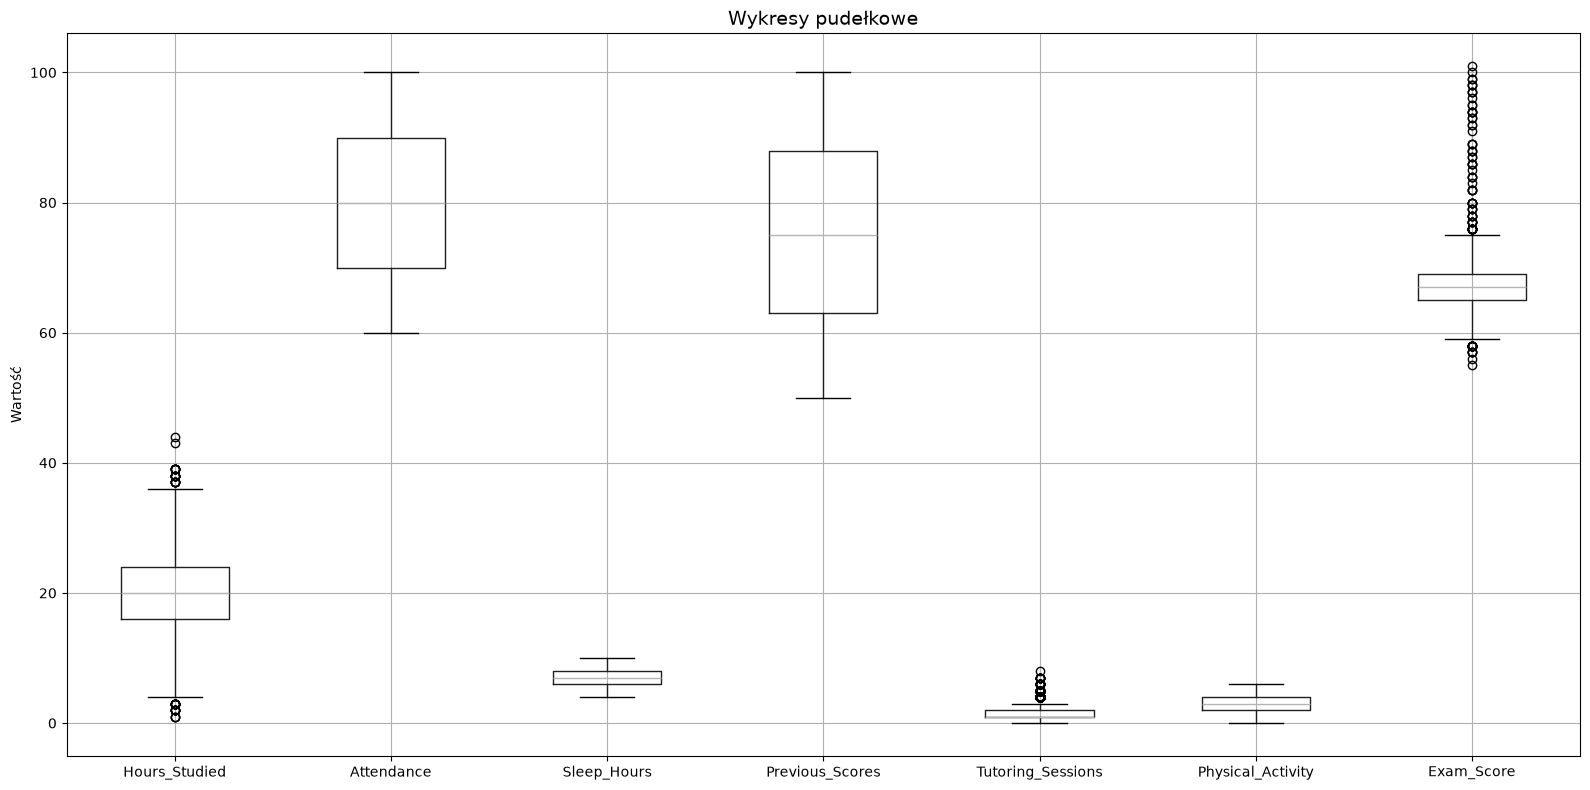

In [13]:
plt.figure(figsize=(16, 8))
X_numeryczne_y.boxplot()
plt.title(
    'Wykresy pudełkowe',
    fontsize=14,
)
plt.ylabel('Wartość')
plt.tight_layout()
plt.show()

## 2. Analiza eksploracyjna

### 2.1. Statystyki opisowe

In [14]:
X_numeryczne_y.describe()

,Hours_Studied,Attendance,Sleep_Hours,Previous_Scores,Tutoring_Sessions,Physical_Activity,Exam_Score
count,6607.000000,6607.000000,6607.00000,6607.000000,6607.000000,6607.000000,6607.000000
mean,19.975329,79.977448,7.02906,75.070531,1.493719,2.967610,67.235659
std,5.990594,11.547475,1.46812,14.399784,1.230570,1.031231,3.890456
min,1.000000,60.000000,4.00000,50.000000,0.000000,0.000000,55.000000
25%,16.000000,70.000000,6.00000,63.000000,1.000000,2.000000,65.000000
50%,20.000000,80.000000,7.00000,75.000000,1.000000,3.000000,67.000000
75%,24.000000,90.000000,8.00000,88.000000,2.000000,4.000000,69.000000
max,44.000000,100.000000,10.00000,100.000000,8.000000,6.000000,101.000000


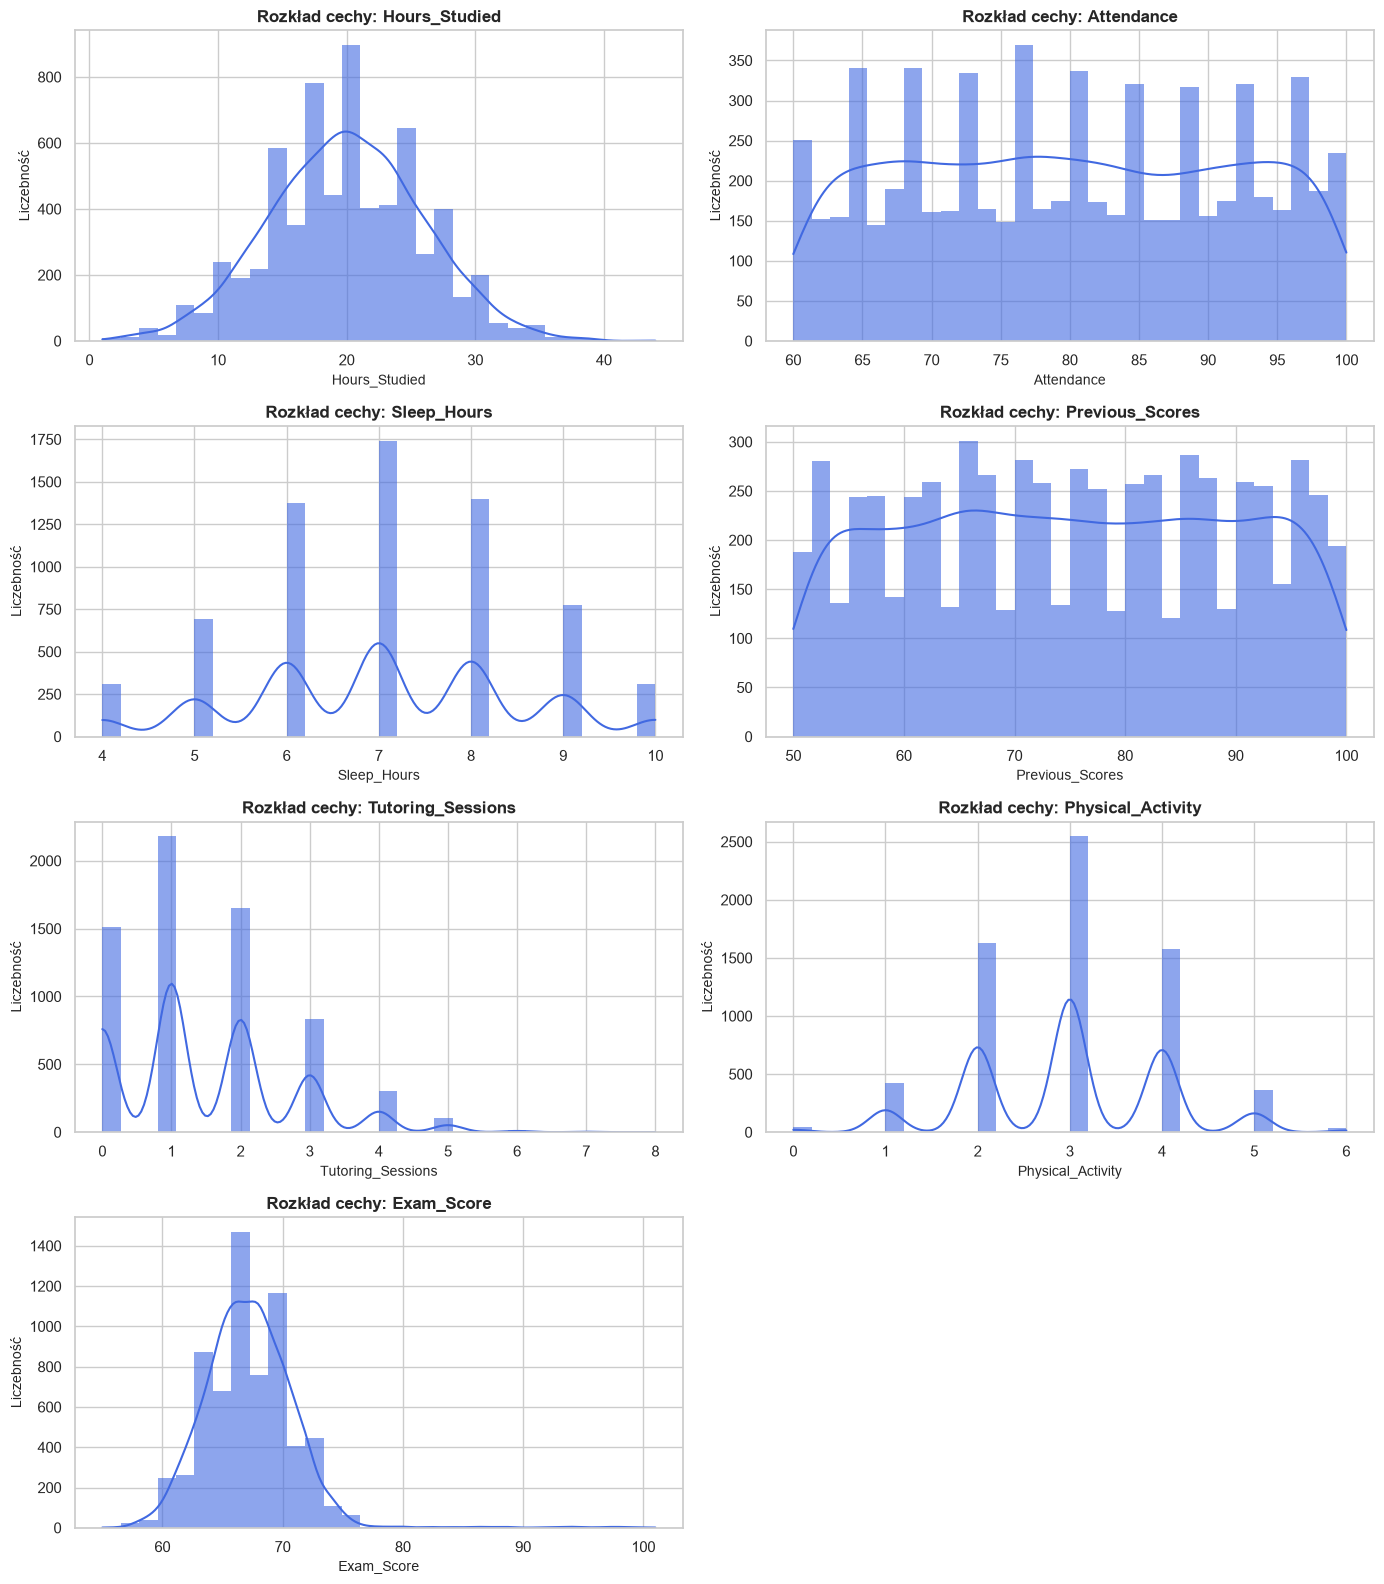

In [15]:
sns.set_theme(style='whitegrid')
fig, axes = plt.subplots(4, 2, figsize=(14, 16))
axes = axes.flatten()

for i, var in enumerate(X_numeryczne_y):
  sns.histplot(
      data=df,
      x=var,
      kde=True,
      ax=axes[i],
      color='royalblue',
      bins=30,
      alpha=0.6,
      edgecolor='none',
  )
  axes[i].set_title(f'Rozkład cechy: {var}', fontsize=12, fontweight='bold')
  axes[i].set_xlabel(var, fontsize=10)
  axes[i].set_ylabel('Liczebność', fontsize=10)

fig.delaxes(axes[-1])

plt.tight_layout()
plt.show()

* Badanie przeprowadzono na **6 607 uczniach.**
* **Wyniki egzaminu końcowego** wśród badanych uczniów wahają się od 55 do 101 punktów. **Przeciętny uczeń zdobywa 67 punktów.** Większość egzaminowanych **otrzymuje od 65 do 69 punktów**, a wyższy wynik osiąga jedynie 25% badanych.
* **Uczniowie na nauce spędzają średnio 20 godzin tygodniowo**, co daje niemal 3 godziny dziennie.
* **Frekwencja większości badanych waha się od 70% do 90%**, ze średnią równą 80%. Najniższa wynosi 60%.
* Większość uczniów **poświęca na sen średnio 7 godzin**, jednak występują ekstremalnie niskie przypadki (4 godziny) oraz ekstremalnie wysokie (10 godzin).
* **Średni wynik z poprzednich egzaminów był wyższy niż z egzaminu końcowego (75 vs 67).**
* Większość uczniów uczęszcza miesięcznie **na 1 lub 2 sesje korepetycji w miesiącu**. Duża liczba badanych nie korzysta wcale z takiego rozwiązania.
* Badani średno przeznaczają **3 godziny tygodniowo na aktywność fizyczną**.

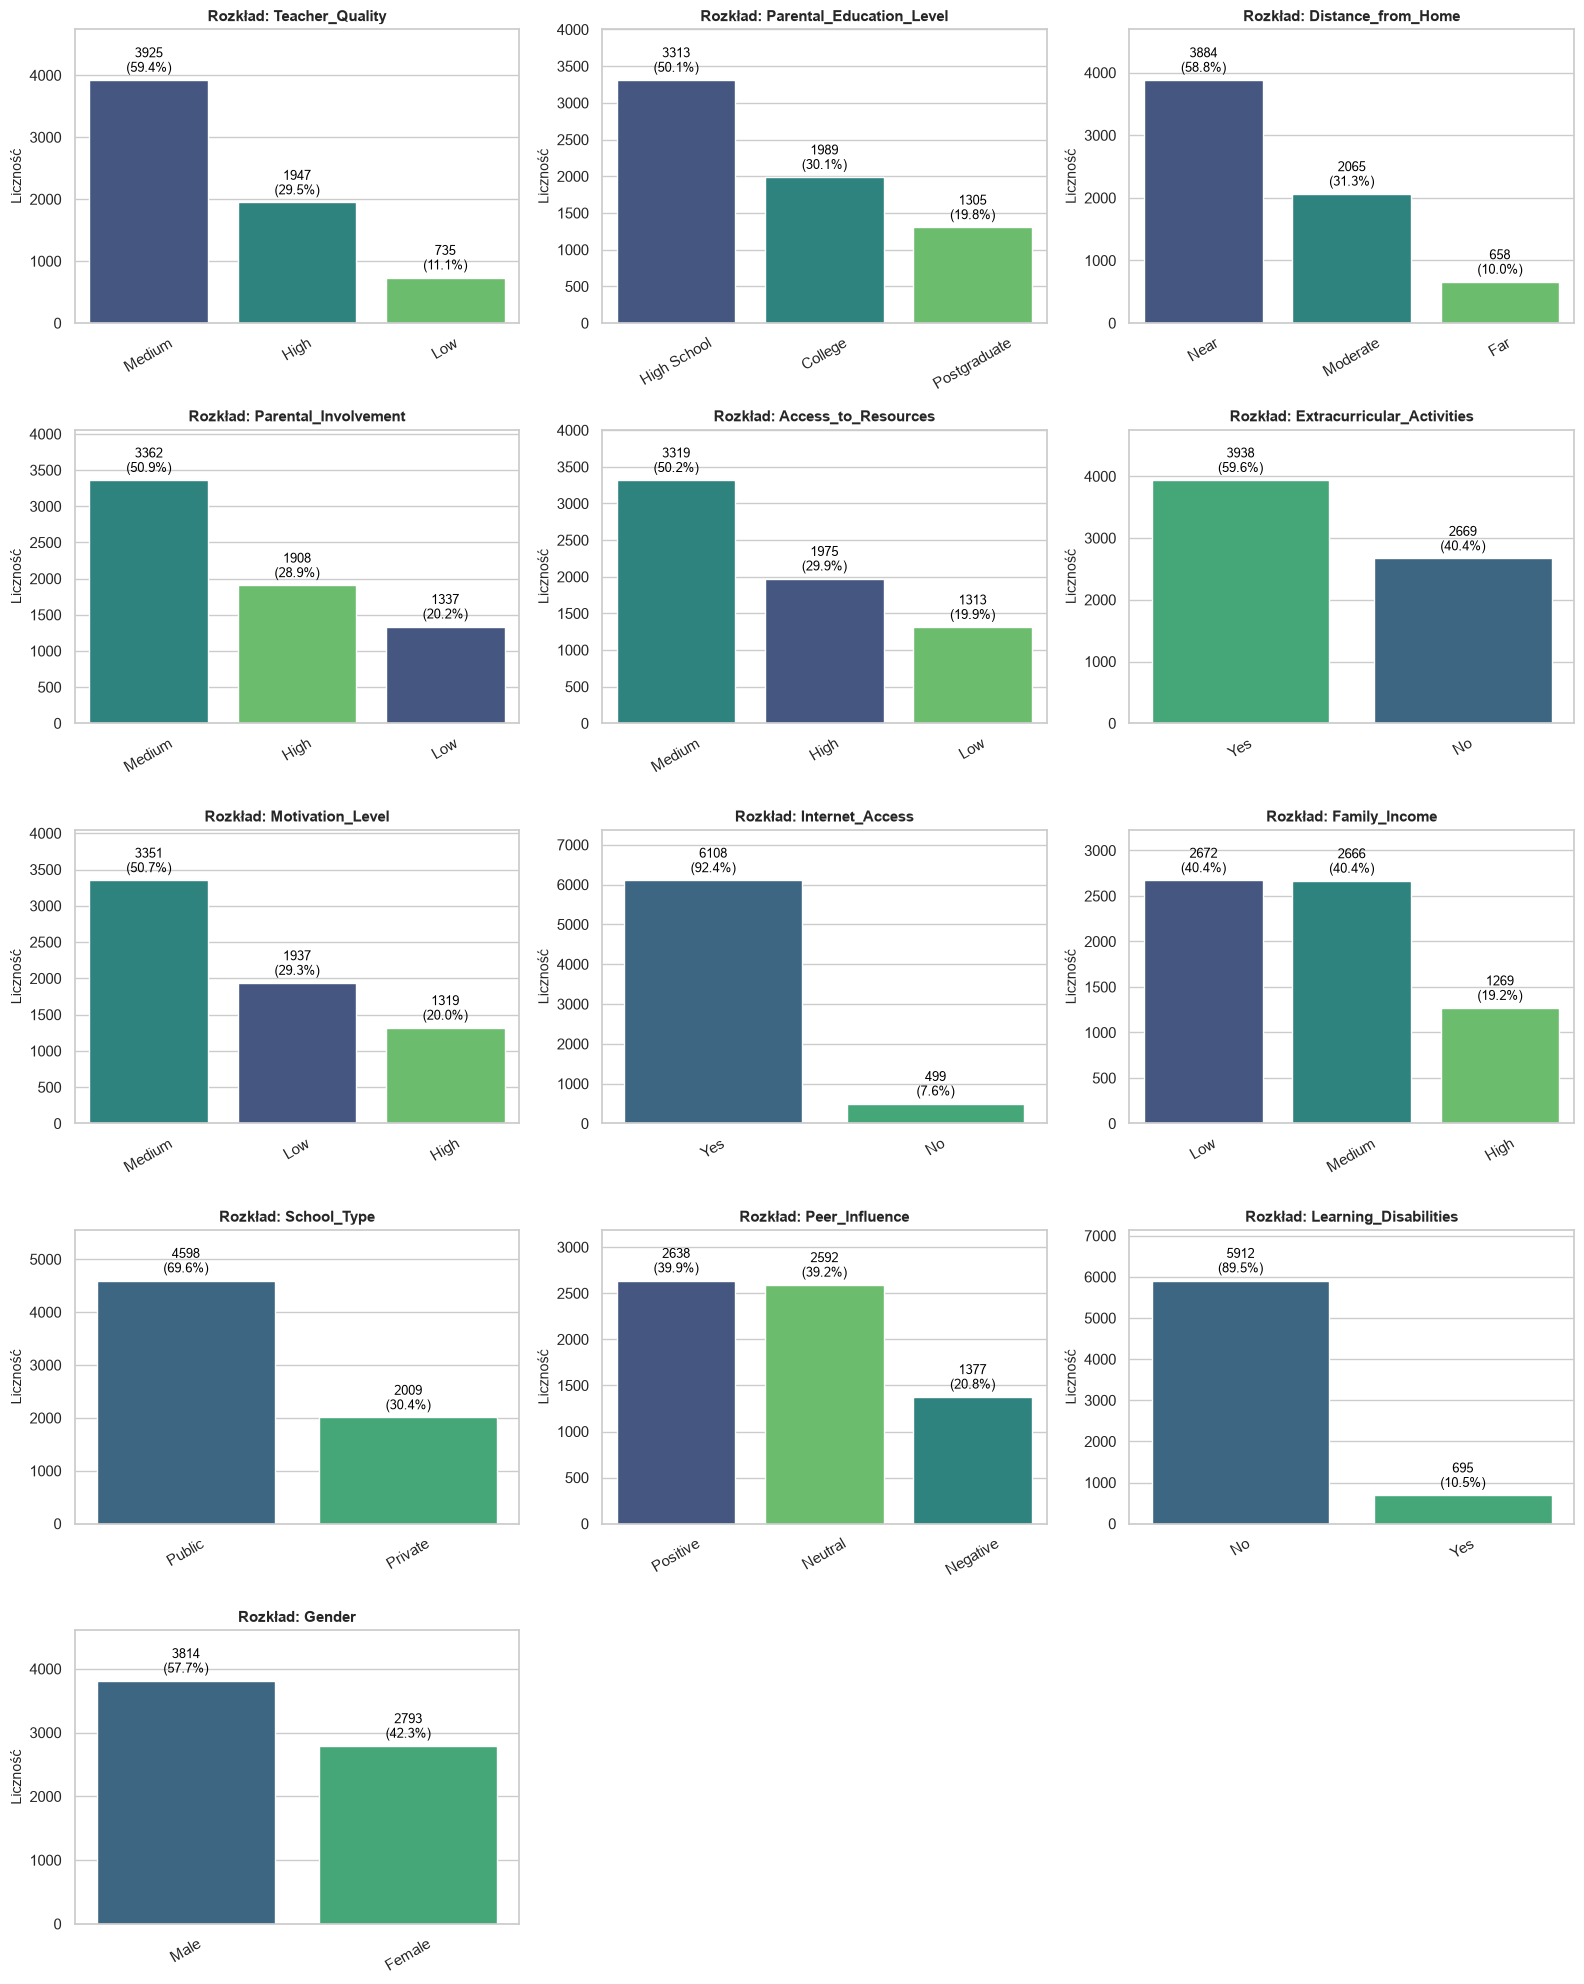

In [16]:
sns.set_theme(style='whitegrid')
n_vars = len(kategoryczne)
n_cols = 3
n_rows = (n_vars + n_cols - 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, n_rows * 4))
axes = axes.flatten()

total_rows = len(df)  

for i, var in enumerate(X_kategoryczne):
  order = df[var].value_counts().index
  ax = axes[i]

  sns.countplot(
      data=df,
      x=var,
      order=order,
      ax=ax,
      palette='viridis',
      hue=var,
      legend=False,
  )

  ax.set_title(f'Rozkład: {var}', fontsize=11, fontweight='bold')
  ax.set_xlabel('', fontsize=10)
  ax.set_ylabel('Liczność', fontsize=10)
  ax.tick_params(axis='x', rotation=30)

  for p in ax.patches:
    height = p.get_height()
    if height > 0:
      percentage = f'{(height / total_rows) * 100:.1f}%'
      count = int(height)
      text = f'{count}\n({percentage})'  
        
      ax.annotate(
          text,
          (p.get_x() + p.get_width() / 2.0, height),
          ha='center',
          va='bottom',
          fontsize=9,
          color='black',
          xytext=(0, 3), 
          textcoords='offset points',
      )

  ax.set_ylim(0, ax.get_ylim()[1] * 1.15)

for j in range(i + 1, len(axes)):
  fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

* W badanej próbie aż połowa uczniów deklaruje **umiarkowany udział rodziców w ich nauce (3 362, 50.9%).** Duży udział ma miejsce w przypadku 28.9% (1 908) uczniów, a mały tylko w 20.2% (1 337).
* **Połowa badanych uczniów ma średni dostęp do zasobów naukowych (3 319, 50.2%).** Wysoki dostęp deklaruje prawie 30% wszystkich uczniów (1 975), a **niski niemal 20%. Niski dostęp do zasobów wspomagających naukę może stanowić problem i powodować gorsze oceny, nie można ignorować tej obserwacji, zwłaszcza w momencie, gdy dotyka to aż 1 313 uczniów.**
* Niemal **60% wszystkich uczniów uczęszcza na dodatkowe zajęcia pozalekcyjne (3 938).**
* **Jedynie 20% badanych deklaruje wysoki poziom motywacji (1 319).** Wśród uczniów przeważa grupa o średnim (3 351, 50.7%) i niskim (1 937, 29.3%) poziomie. Warto zwrócić uwagę na poziom motywacji i wpływać na ich samozaparcie.
* **Brak dostępu do internetu nie stanowi problemu w grupie badanych uczniów.** Zgłasza go jedynie 7.6% z nich (499). Mimo to, nie można ignorować potencjalnego negatywnego wpływu na wyniki szkolne, nawet wśród tak nielicznej grupy osób.
* **Większość uczniów pochodzi z rodzin o niskim (2 672, 40.4%) i średnim (2 666, 40.4%) dochodzie.**
* **11.1% osób (735) zgłasza niski poziom jakości nauczania.** Stanowi to sygnał do pogłębionej analizy i podjęcia działań w tym zakresie.
* Spośród badanych uczniów, prawie 70% z nich uczęszcza do szkół publicznych (4 598). Szkoły prywatne stanowią 30.4% (2 009).
* **Wpływ rówieśników na edukację jest przez większość uczniów oceniany na pozytywny (2 638, 39.9%) lub neutralny (2 592, 39.2%)**, jednak istnieje grupa określający go jako negatywny (1 377, 20.8%), co jest alarmujące. 
* **Grupa uczniów zmagających się z trudnościami w nauce stanowi 10.5% badanych (695).** Są to osoby, które potrzebują odpowiedniego podejścia i toku nauki.
* Najliczniejsza grupa uczniów wskazuje, że ich rodzice mają **wykształcenie średnie (3 313, 50.1%).**
* **10% badanych określa odległość do domu jako dużą (658)**, co potencjalnie może mieć negatywny wpływ na wyniki. 
* Wśród badanych **przeważają mężczyźni (3 814, 57.7%).** Kobiety stanowią 42.3% grupy (2 793).

### 2.2. Test normalności D'Agostino-Pearsona i wykresy Q-Q


========== ZMIENNA: Teacher_Quality ==========

Grupa: High (Liczebność n = 1947)
Statystyka testowa: 922.7980
p-value: 4.1395e-201
Wynik: Odrzucamy H0. Rozkład NIE jest normalny).


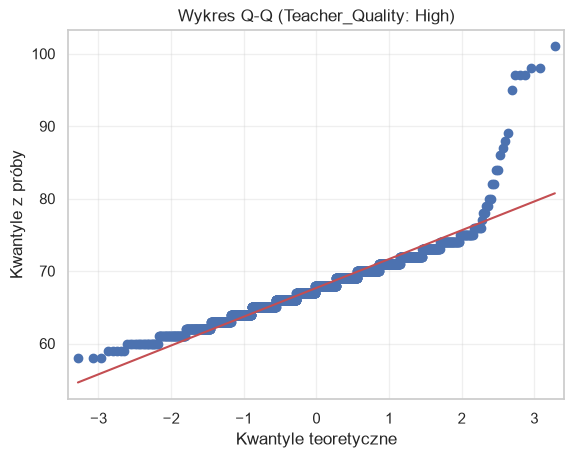

Grupa: Low (Liczebność n = 735)
Statystyka testowa: 290.0527
p-value: 1.0372e-63
Wynik: Odrzucamy H0. Rozkład NIE jest normalny).


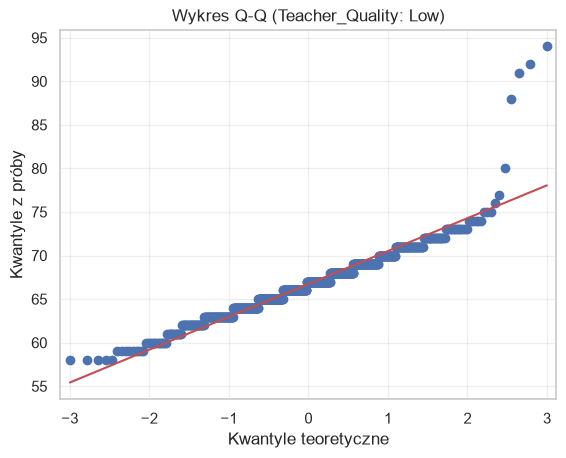

Grupa: Medium (Liczebność n = 3925)
Statystyka testowa: 1560.2853
p-value: 0.0000e+00
Wynik: Odrzucamy H0. Rozkład NIE jest normalny).


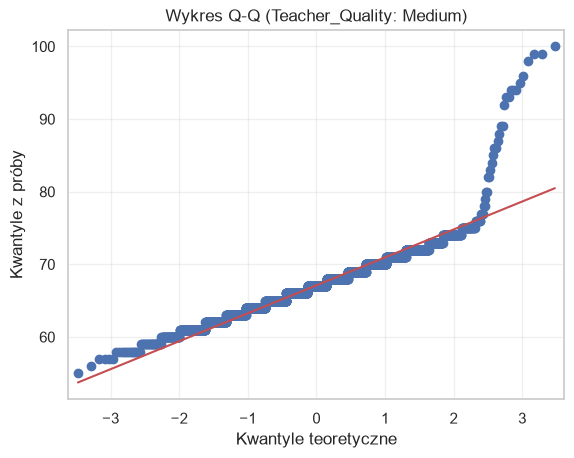


========== ZMIENNA: Parental_Education_Level ==========

Grupa: College (Liczebność n = 1989)
Statystyka testowa: 742.6895
p-value: 5.3335e-162
Wynik: Odrzucamy H0. Rozkład NIE jest normalny).


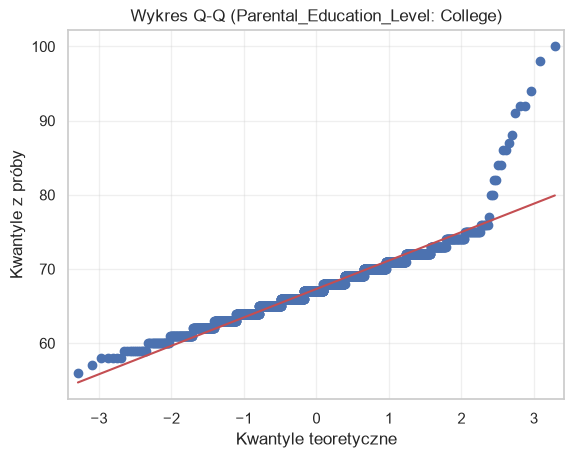

Grupa: High School (Liczebność n = 3313)
Statystyka testowa: 1539.4999
p-value: 0.0000e+00
Wynik: Odrzucamy H0. Rozkład NIE jest normalny).


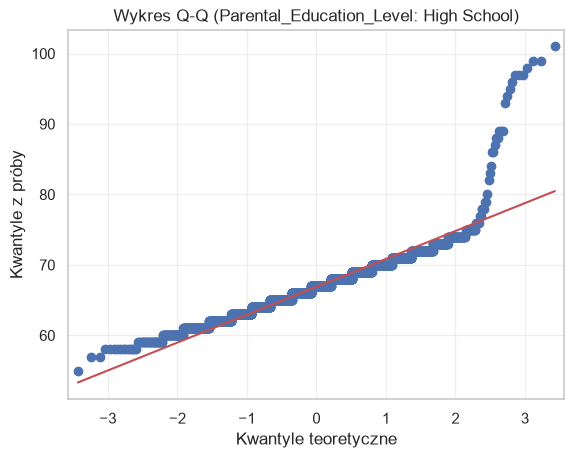

Grupa: Postgraduate (Liczebność n = 1305)
Statystyka testowa: 540.8541
p-value: 3.5895e-118
Wynik: Odrzucamy H0. Rozkład NIE jest normalny).


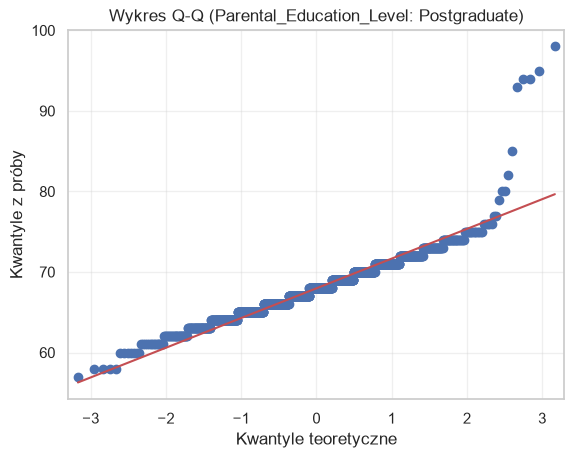


========== ZMIENNA: Distance_from_Home ==========

Grupa: Far (Liczebność n = 658)
Statystyka testowa: 320.2714
p-value: 2.8441e-70
Wynik: Odrzucamy H0. Rozkład NIE jest normalny).


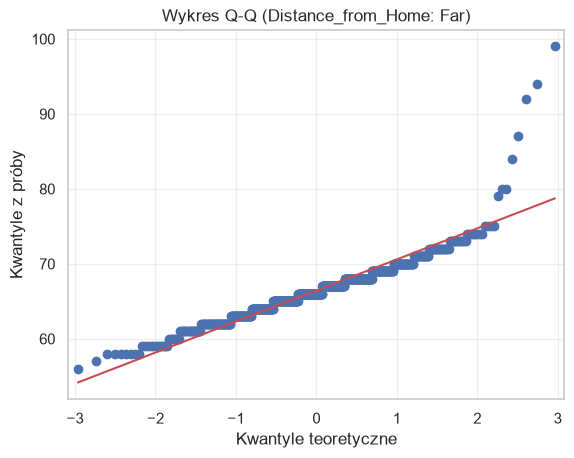

Grupa: Moderate (Liczebność n = 2065)
Statystyka testowa: 822.2038
p-value: 2.8887e-179
Wynik: Odrzucamy H0. Rozkład NIE jest normalny).


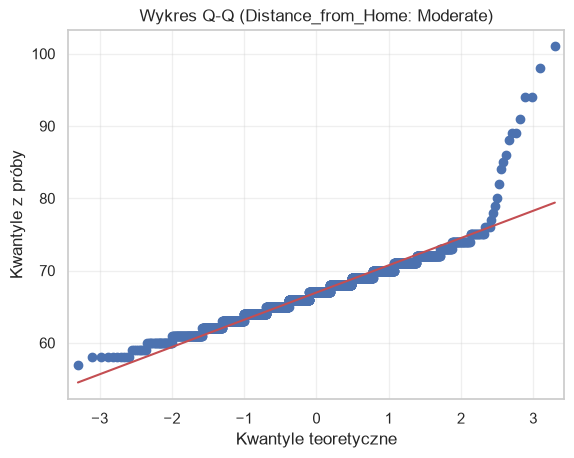

Grupa: Near (Liczebność n = 3884)
Statystyka testowa: 1666.0689
p-value: 0.0000e+00
Wynik: Odrzucamy H0. Rozkład NIE jest normalny).


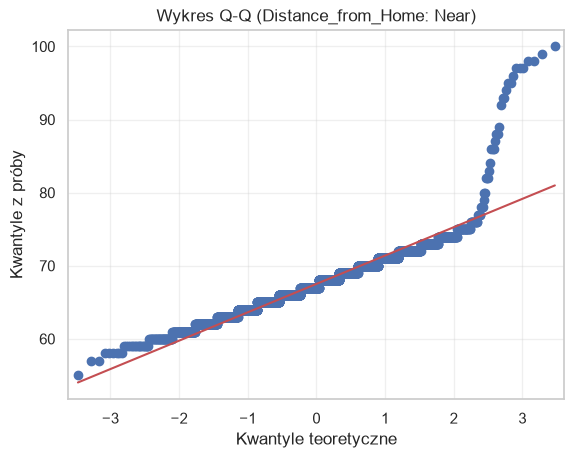


========== ZMIENNA: Parental_Involvement ==========

Grupa: High (Liczebność n = 1908)
Statystyka testowa: 922.0894
p-value: 5.8996e-201
Wynik: Odrzucamy H0. Rozkład NIE jest normalny).


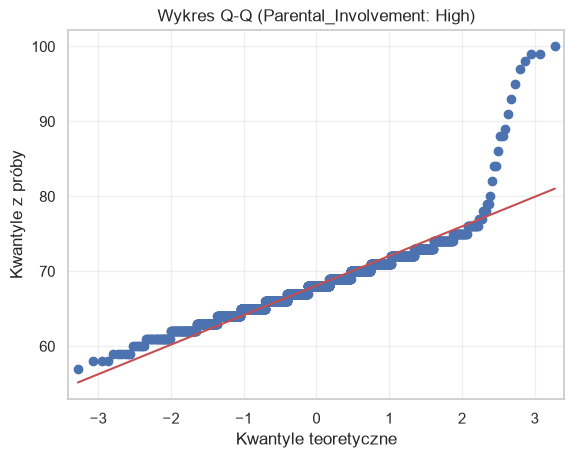

Grupa: Low (Liczebność n = 1337)
Statystyka testowa: 696.5788
p-value: 5.4933e-152
Wynik: Odrzucamy H0. Rozkład NIE jest normalny).


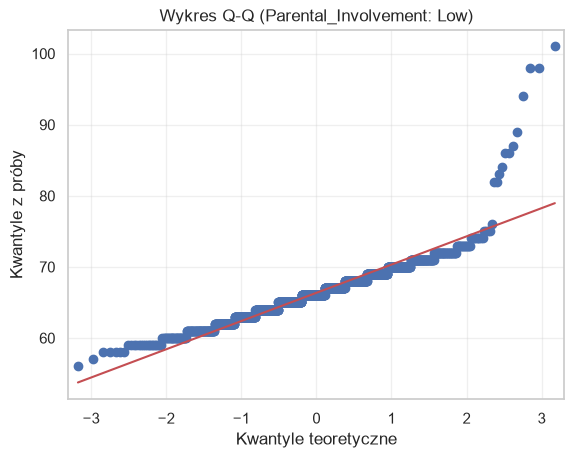

Grupa: Medium (Liczebność n = 3362)
Statystyka testowa: 1201.1352
p-value: 1.5025e-261
Wynik: Odrzucamy H0. Rozkład NIE jest normalny).


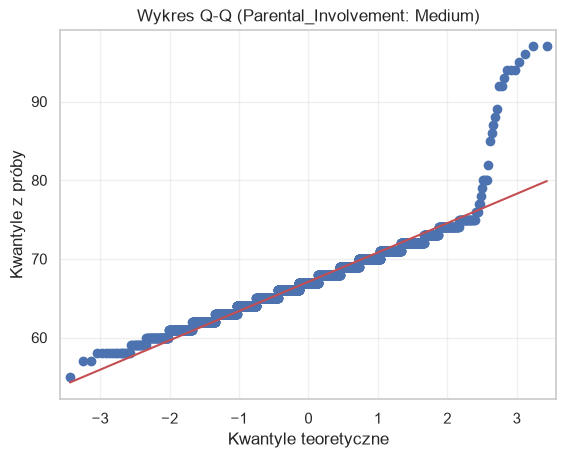


========== ZMIENNA: Access_to_Resources ==========

Grupa: High (Liczebność n = 1975)
Statystyka testowa: 766.9323
p-value: 2.9024e-167
Wynik: Odrzucamy H0. Rozkład NIE jest normalny).


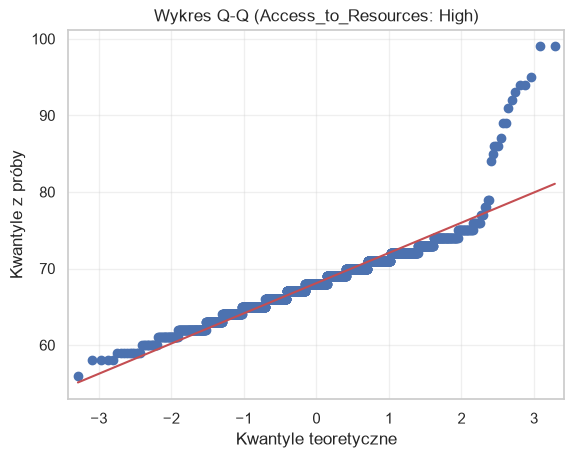

Grupa: Low (Liczebność n = 1313)
Statystyka testowa: 391.8567
p-value: 8.1172e-86
Wynik: Odrzucamy H0. Rozkład NIE jest normalny).


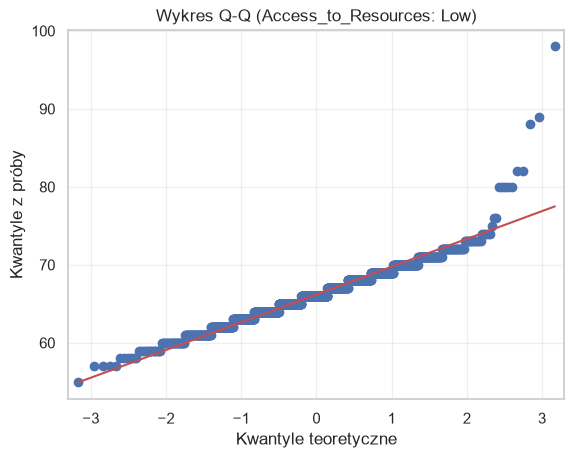

Grupa: Medium (Liczebność n = 3319)
Statystyka testowa: 1634.8433
p-value: 0.0000e+00
Wynik: Odrzucamy H0. Rozkład NIE jest normalny).


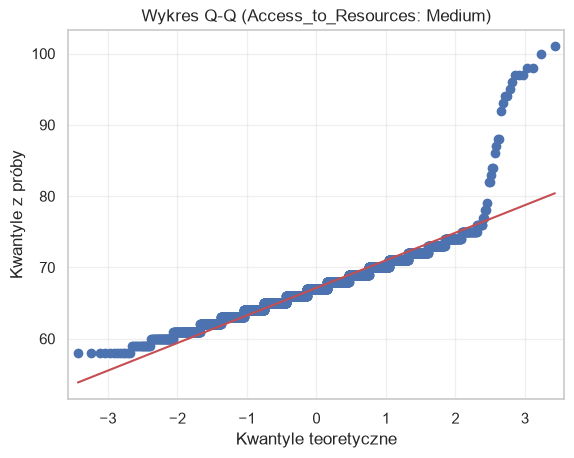


========== ZMIENNA: Extracurricular_Activities ==========

Grupa: No (Liczebność n = 2669)
Statystyka testowa: 946.5749
p-value: 2.8436e-206
Wynik: Odrzucamy H0. Rozkład NIE jest normalny).


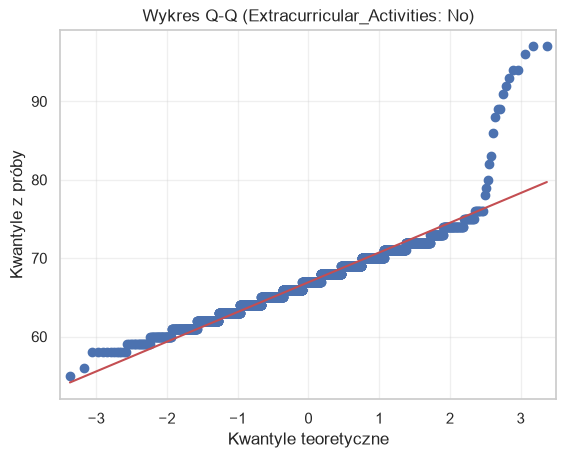

Grupa: Yes (Liczebność n = 3938)
Statystyka testowa: 1788.9611
p-value: 0.0000e+00
Wynik: Odrzucamy H0. Rozkład NIE jest normalny).


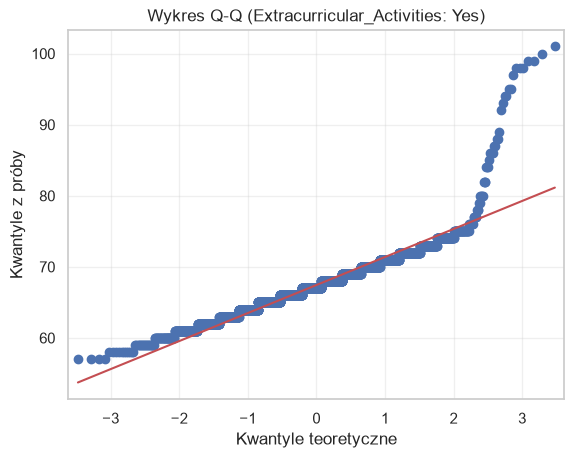


========== ZMIENNA: Motivation_Level ==========

Grupa: High (Liczebność n = 1319)
Statystyka testowa: 445.5154
p-value: 1.8095e-97
Wynik: Odrzucamy H0. Rozkład NIE jest normalny).


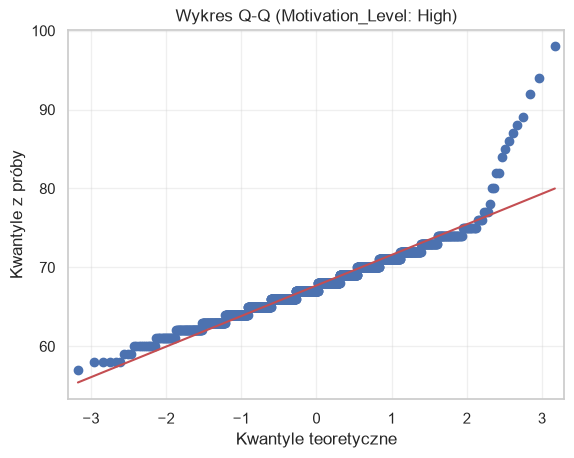

Grupa: Low (Liczebność n = 1937)
Statystyka testowa: 914.1481
p-value: 3.1280e-199
Wynik: Odrzucamy H0. Rozkład NIE jest normalny).


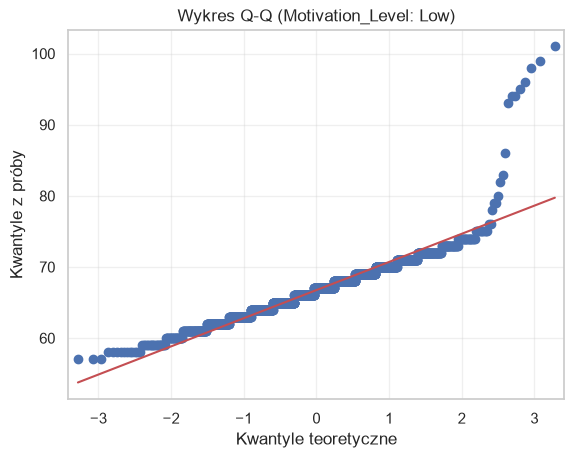

Grupa: Medium (Liczebność n = 3351)
Statystyka testowa: 1445.4935
p-value: 0.0000e+00
Wynik: Odrzucamy H0. Rozkład NIE jest normalny).


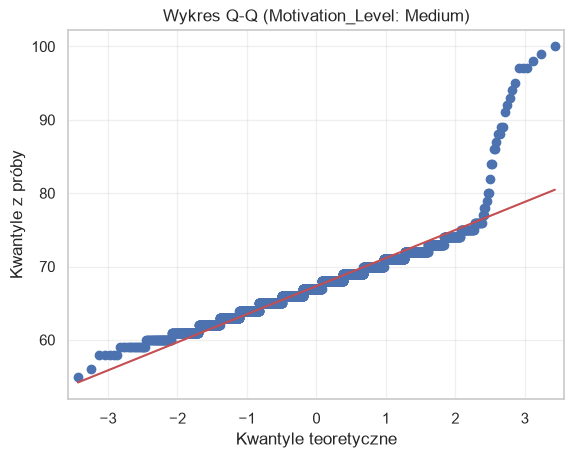


========== ZMIENNA: Internet_Access ==========

Grupa: No (Liczebność n = 499)
Statystyka testowa: 314.7193
p-value: 4.5665e-69
Wynik: Odrzucamy H0. Rozkład NIE jest normalny).


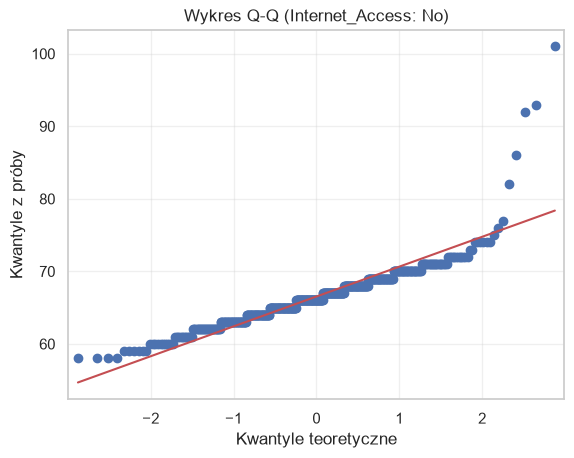

Grupa: Yes (Liczebność n = 6108)
Statystyka testowa: 2445.2618
p-value: 0.0000e+00
Wynik: Odrzucamy H0. Rozkład NIE jest normalny).


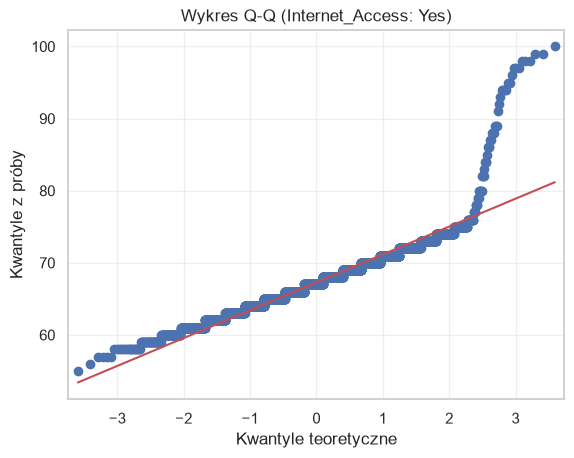


========== ZMIENNA: Family_Income ==========

Grupa: High (Liczebność n = 1269)
Statystyka testowa: 746.0498
p-value: 9.9388e-163
Wynik: Odrzucamy H0. Rozkład NIE jest normalny).


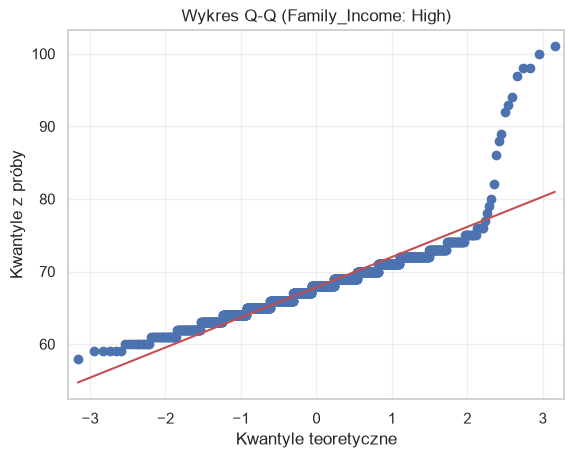

Grupa: Low (Liczebność n = 2672)
Statystyka testowa: 918.7913
p-value: 3.0690e-200
Wynik: Odrzucamy H0. Rozkład NIE jest normalny).


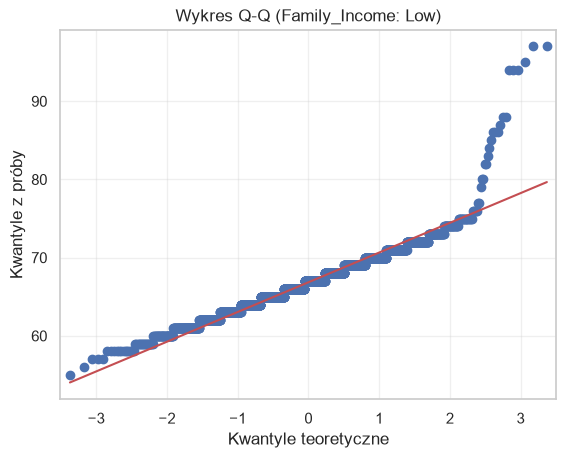

Grupa: Medium (Liczebność n = 2666)
Statystyka testowa: 1017.2119
p-value: 1.3039e-221
Wynik: Odrzucamy H0. Rozkład NIE jest normalny).


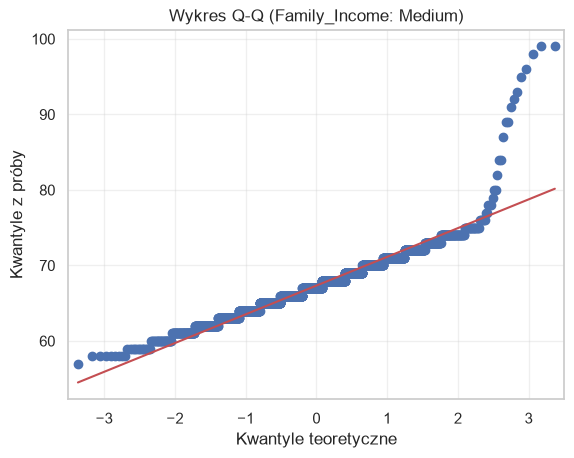


========== ZMIENNA: School_Type ==========

Grupa: Private (Liczebność n = 2009)
Statystyka testowa: 836.5504
p-value: 2.2151e-182
Wynik: Odrzucamy H0. Rozkład NIE jest normalny).


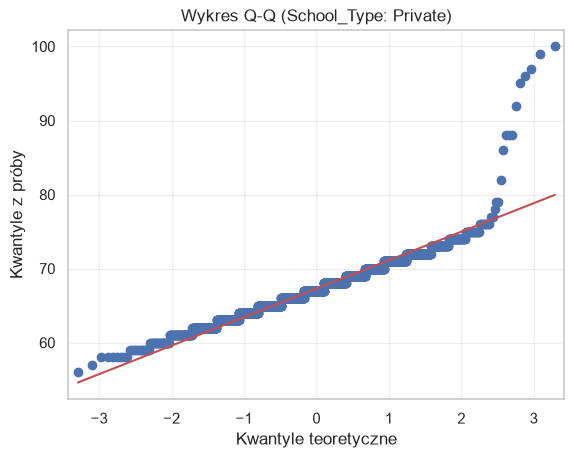

Grupa: Public (Liczebność n = 4598)
Statystyka testowa: 1925.7830
p-value: 0.0000e+00
Wynik: Odrzucamy H0. Rozkład NIE jest normalny).


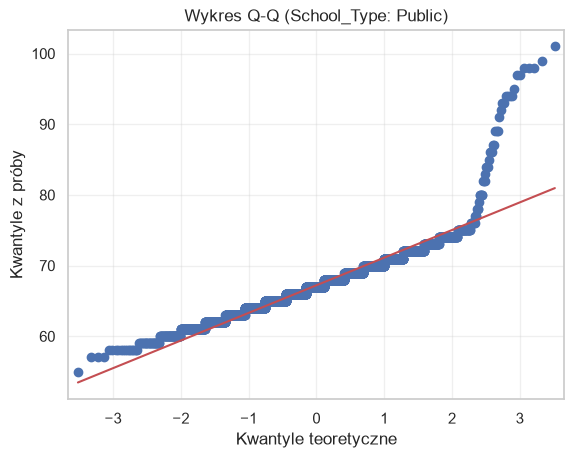


========== ZMIENNA: Peer_Influence ==========

Grupa: Negative (Liczebność n = 1377)
Statystyka testowa: 643.8071
p-value: 1.5815e-140
Wynik: Odrzucamy H0. Rozkład NIE jest normalny).


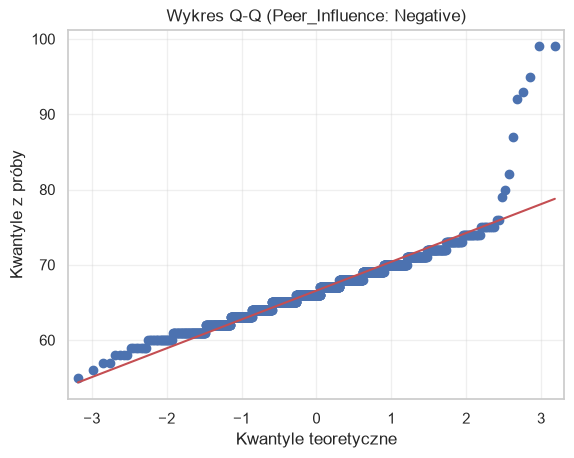

Grupa: Neutral (Liczebność n = 2592)
Statystyka testowa: 1033.1943
p-value: 4.4127e-225
Wynik: Odrzucamy H0. Rozkład NIE jest normalny).


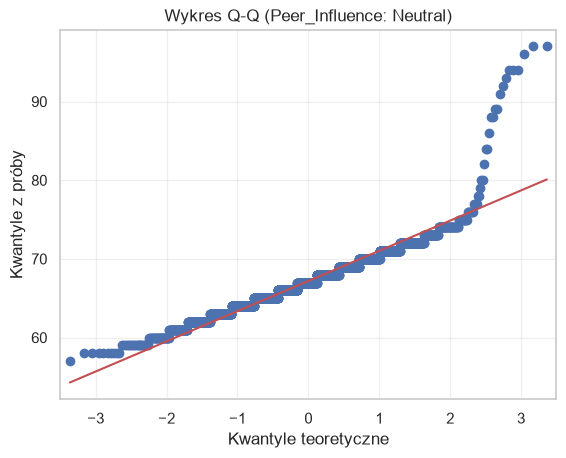

Grupa: Positive (Liczebność n = 2638)
Statystyka testowa: 1137.3275
p-value: 1.0776e-247
Wynik: Odrzucamy H0. Rozkład NIE jest normalny).


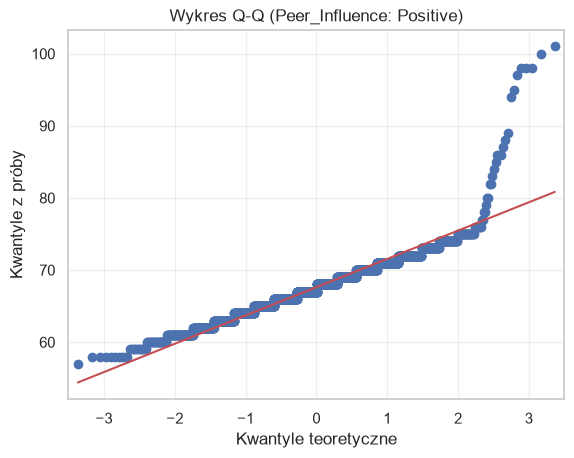


========== ZMIENNA: Learning_Disabilities ==========

Grupa: No (Liczebność n = 5912)
Statystyka testowa: 2585.0841
p-value: 0.0000e+00
Wynik: Odrzucamy H0. Rozkład NIE jest normalny).


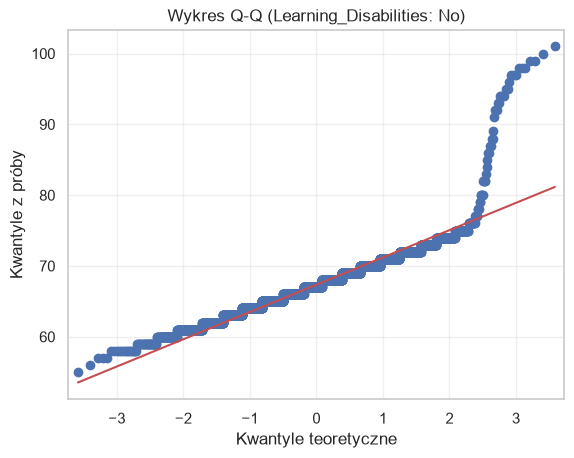

Grupa: Yes (Liczebność n = 695)
Statystyka testowa: 213.8850
p-value: 3.5930e-47
Wynik: Odrzucamy H0. Rozkład NIE jest normalny).


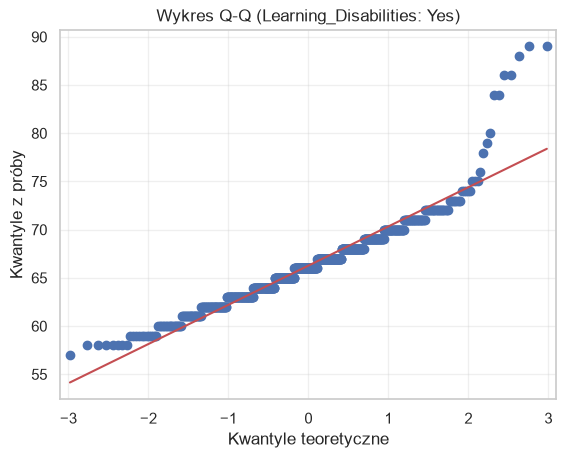


========== ZMIENNA: Gender ==========

Grupa: Female (Liczebność n = 2793)
Statystyka testowa: 1391.4996
p-value: 6.9136e-303
Wynik: Odrzucamy H0. Rozkład NIE jest normalny).


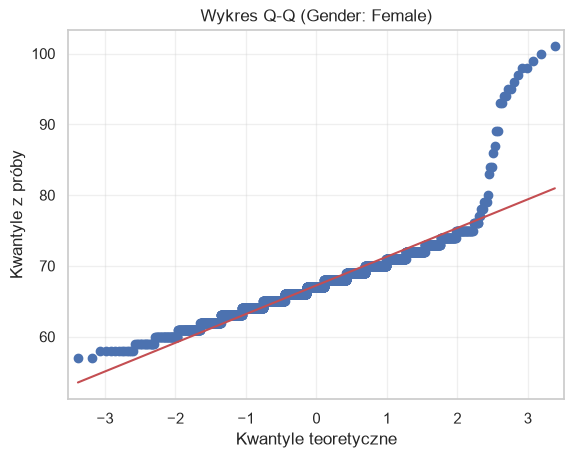

Grupa: Male (Liczebność n = 3814)
Statystyka testowa: 1278.2772
p-value: 2.6646e-278
Wynik: Odrzucamy H0. Rozkład NIE jest normalny).


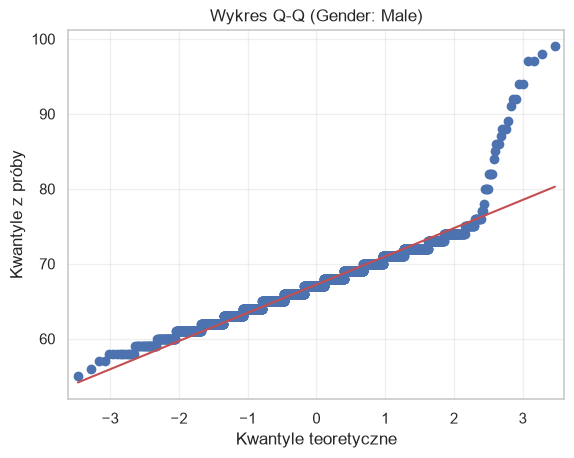

In [22]:
for col in X_kategoryczne:
    print(f"\n{'='*10} ZMIENNA: {col} {'='*10}\n")
    
    for name, group in df.groupby(col):

        grupowanie = group['Exam_Score']

        #test 
        stat, p_value = stats.normaltest(grupowanie)

        print(f'Grupa: {name} (Liczebność n = {len(grupowanie)})')
        print(f'Statystyka testowa: {stat:.4f}')
        print(f'p-value: {p_value:.4e}')

        if p_value < 0.05:
            print('Wynik: Odrzucamy H0. Rozkład NIE jest normalny).')
        else:
            print('Wynik: Brak podstaw do odrzucenia H0. Rozkład jest normalny).')

        #wykres q-q
        fig = sm.qqplot(grupowanie, line='s')
        plt.title(f'Wykres Q-Q ({col}: {name})')
        plt.xlabel('Kwantyle teoretyczne')
        plt.ylabel('Kwantyle z próby')
        plt.grid(True, alpha=0.3)
        plt.show()

Założenie o normalności, wymagane do przeprowadzenia testu ANOVA, nie zostało spełnione. Na wykresach Q-Q zauważyć można odstające ogony (obserwacje ekstremalne). **Brak normalności nakazuje skorzystanie z testów NIEPARAMETRYCZNYCH.**

### 2.3. Test jednorodności wariancji Levene'a

In [23]:
for col in X_kategoryczne:

    grupy = [group['Exam_Score'] for name, group in df.groupby(col)]

    levene_stat, levene_p = stats.levene(*grupy, center='mean')

    print(f'=== TEST LEVENE\'A (ZMIENNA: {col}) ===')
    print(f'Statystyka F: {levene_stat:.4f}')
    print(f'p-value: {levene_p:.4e}')

    if levene_p < 0.05:
        print('Wynik: Odrzucamy H0. Wariancje w grupach NIE są jednorodne.')
    else:
        print('Wynik: Brak podstaw do odrzucenia H0. Wariancje są jednorodne.')

    print("")

=== TEST LEVENE'A (ZMIENNA: Teacher_Quality) ===
Statystyka F: 0.7302
p-value: 4.8183e-01
Wynik: Brak podstaw do odrzucenia H0. Wariancje są jednorodne.

=== TEST LEVENE'A (ZMIENNA: Parental_Education_Level) ===
Statystyka F: 1.5859
p-value: 2.0485e-01
Wynik: Brak podstaw do odrzucenia H0. Wariancje są jednorodne.

=== TEST LEVENE'A (ZMIENNA: Distance_from_Home) ===
Statystyka F: 1.1127
p-value: 3.2872e-01
Wynik: Brak podstaw do odrzucenia H0. Wariancje są jednorodne.

=== TEST LEVENE'A (ZMIENNA: Parental_Involvement) ===
Statystyka F: 0.5879
p-value: 5.5552e-01
Wynik: Brak podstaw do odrzucenia H0. Wariancje są jednorodne.

=== TEST LEVENE'A (ZMIENNA: Access_to_Resources) ===
Statystyka F: 2.5681
p-value: 7.6759e-02
Wynik: Brak podstaw do odrzucenia H0. Wariancje są jednorodne.

=== TEST LEVENE'A (ZMIENNA: Extracurricular_Activities) ===
Statystyka F: 0.0709
p-value: 7.9003e-01
Wynik: Brak podstaw do odrzucenia H0. Wariancje są jednorodne.

=== TEST LEVENE'A (ZMIENNA: Motivation_Level

## 3. Analiza zależności

### 3.0. Funkcje

In [24]:
def u_mann_whitney(df, group_col, target_col='Exam_Score'):
    
  #grupy 
  grupy = df[group_col].unique()

  val_1, val_2 = grupy[0], grupy[1]

  grupa_1 = df[df[group_col] == val_1][target_col]
  grupa_2 = df[df[group_col] == val_2][target_col]

  #mediany
  print(f'\n=== MEDIANY {target_col} wg: {group_col} ===')
  mediany = (
      df.groupby(group_col)[target_col]
      .median()
      .reset_index(name=f'Mediana_{target_col}')
  )
  print(mediany.to_string(index=False))
  print("")

  #test
  print(f'=== TEST U MANNA-WHITNEYA DLA: {group_col} ({val_1} vs {val_2}) ===')
  print(f'Liczebność grupy {val_1}: {len(grupa_1)}')
  print(f'Liczebność grupy {val_2}: {len(grupa_2)}')

  u_stat, p_value = stats.mannwhitneyu(
      grupa_1, grupa_2, alternative='two-sided'
  )

  print(f'Statystyka U: {u_stat:.4f}')
  print(f'p-value: {p_value:.4e}')

  #interpretacja
  if p_value < 0.05:
    print('Wynik: Odrzucamy H0. Istnieje statystycznie istotna różnica między grupami.')
  else:
    print('Wynik: Brak podstaw do odrzucenia H0. Brak istotnych różnic między grupami.')

In [25]:
def kruskal_wallis(df, group_col, target_col='Exam_Score', palette='Dark2', order=None):

  #grupy
  grupy = [
      group[target_col].dropna().values
      for name, group in df.groupby(group_col)
  ]

  #wykresy
  plt.figure(figsize=(8, 6))
  sns.boxplot(
      data=df,
      x=group_col,
      y=target_col,
      hue=group_col,
      legend=False,
      palette=palette,
      order=order,
  )
  plt.title(f'Rozkład {target_col} wg {group_col}', fontsize=13, pad=12)
  plt.xlabel(group_col, fontsize=11)
  plt.ylabel(f'Wynik z egzaminu ({target_col})', fontsize=11)
  plt.tight_layout()
  plt.show()

  #mediany
  print(f'\n=== MEDIANY {target_col} wg: {group_col} ===')
  mediany = (
      df.groupby(group_col)[target_col]
      .median()
      .reset_index(name=f'Mediana_{target_col}')
  )
  print(mediany.to_string(index=False))
  print("")

  #test  
  print(f'=== TEST KRUSKALA-WALLISA DLA ZMIENNEJ: {group_col} (Liczebność grup:'f' {len(grupy)}) ===')
  for name, group in df.groupby(group_col):
    print(f'Grupa "{name}": n = {len(group[target_col].dropna())}')

  h_stat, p_value = stats.kruskal(*grupy)

  print(f'\nStatystyka H (H-value): {h_stat:.4f}')
  print(f'p-value: {p_value:.4e}')

  #interpretacja
  if p_value < 0.05:
    print('Wynik: Odrzucamy H0. Przynajmniej jedna grupa istotnie różni się od pozostałych pod względem wyników.')
      
  #test post-hoc dunna
    print('\n=== TEST POST-HOC DUNNA (p-value adjusted: Bonferroni) ===')  
    dunn_res = sp.posthoc_dunn(df, val_col=target_col, group_col=group_col, p_adjust='bonferroni')
    print(dunn_res)
    print('Wartości w macierzy mniejsze niż 0.05 oznaczają pary grup, które istotnie się różnią.')
  else:
    print('Wynik: Brak podstaw do odrzucenia H0. Brak istotnych różnic między grupami.')

In [26]:
def korelacja(df, x, y='Exam_Score'):
    
  data = df[[x, y]]

  print(f'=== ANALIZA KORELACJI: {x} vs {y} ===')
  print(f'Liczebność par (n): {len(data)}')

  corr_spear, p_spear = stats.spearmanr(data[x], data[y])
  print(f'Korelacja Spearmana (rho): {corr_spear:.4f} | p-value: {p_spear:.4e}')

  corr_pears, p_pears = stats.pearsonr(data[x], data[y])
  print(f'Korelacja Pearsona (r):    {corr_pears:.4f} | p-value: {p_pears:.4e}')

  #interpretacja
  if p_spear < 0.05:
    direction = (
        'dodatnia'
        if corr_spear > 0
        else 'ujemna'
    )
    print(f'\nWynik: Istnieje statystycznie istotna zależność ({direction}). \n')
      
  else:
    print('\nWynik: Brak istotnej zależności statystycznej między zmiennymi. \n')

### 3.1. Test U Manna-Whitneya

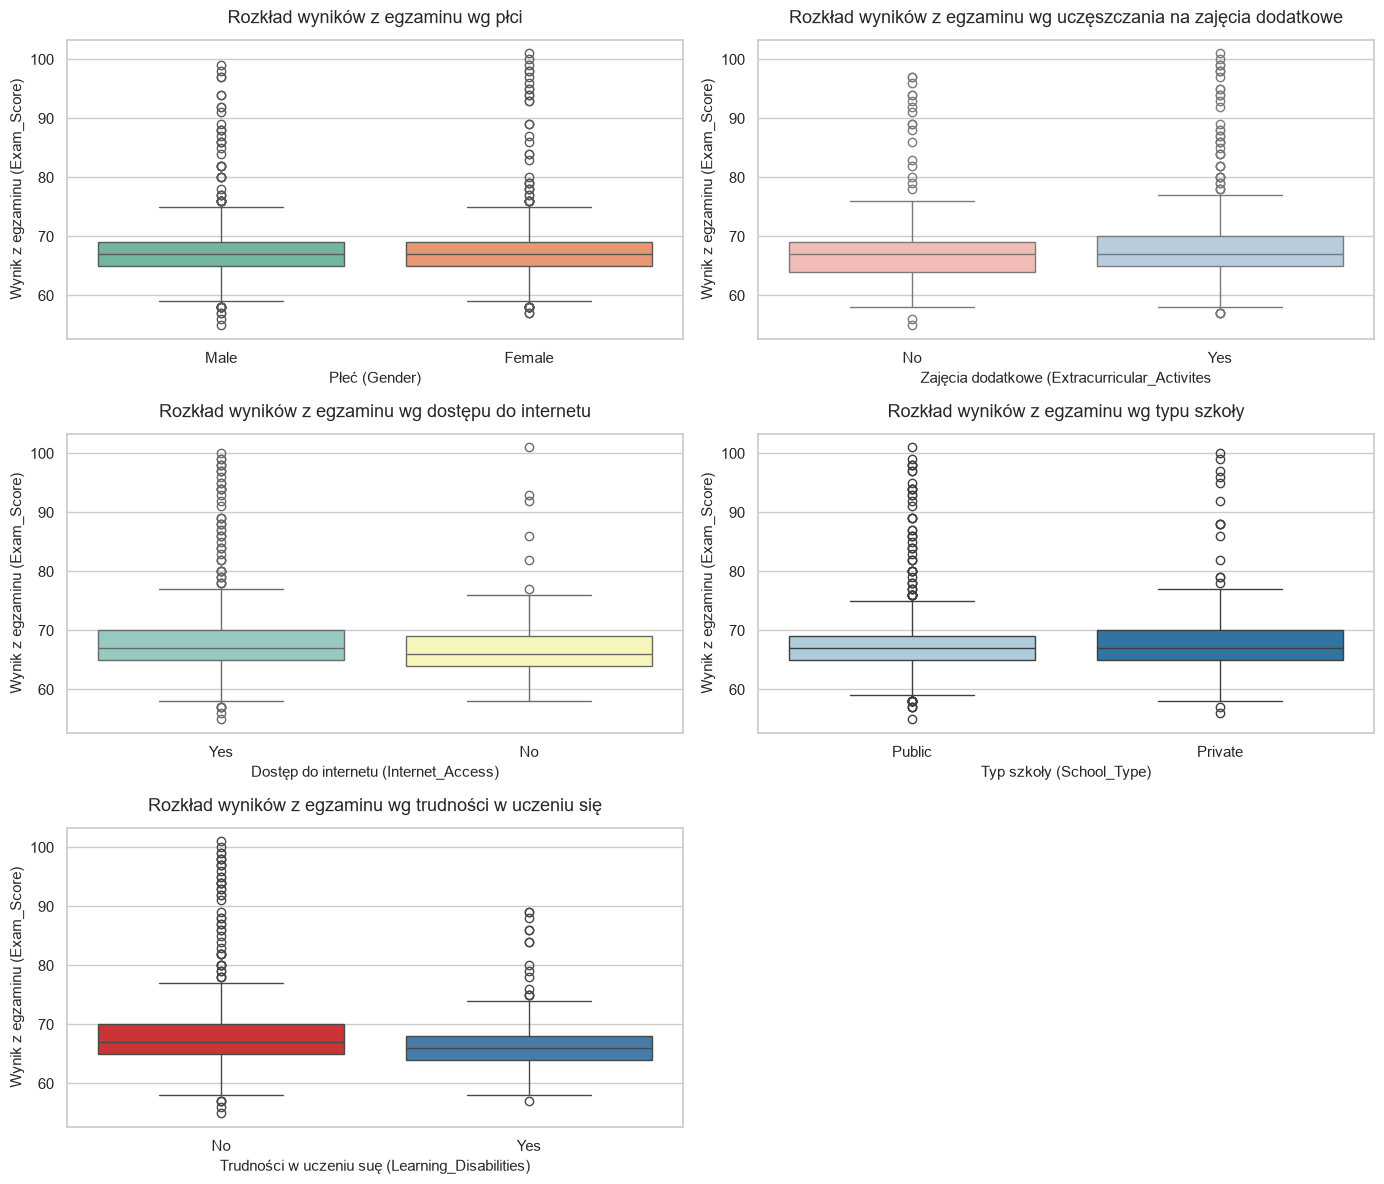

In [27]:
fig, axes = plt.subplots(3, 2, figsize=(14, 12))
axes = axes.flatten()  

# wykres 1
sns.boxplot(
    data=df,
    x='Gender',
    y='Exam_Score',
    hue='Gender',
    legend=False,
    palette='Set2',
    order=['Male', 'Female'],
    ax=axes[0],  
)
axes[0].set_title('Rozkład wyników z egzaminu wg płci', fontsize=13, pad=12)
axes[0].set_xlabel('Płeć (Gender)', fontsize=11)
axes[0].set_ylabel('Wynik z egzaminu (Exam_Score)', fontsize=11)

# wykres 2
sns.boxplot(
    data=df,
    x='Extracurricular_Activities',
    y='Exam_Score',
    hue='Extracurricular_Activities',
    legend=False,
    palette='Pastel1',
    ax=axes[1],  
)
axes[1].set_title(
    'Rozkład wyników z egzaminu wg uczęszczania na zajęcia dodatkowe', fontsize=13, pad=12)
axes[1].set_xlabel('Zajęcia dodatkowe (Extracurricular_Activites', fontsize=11)
axes[1].set_ylabel('Wynik z egzaminu (Exam_Score)', fontsize=11)

# wykres 3
sns.boxplot(
    data=df,
    x='Internet_Access',
    y='Exam_Score',
    hue='Internet_Access',
    legend=False,
    palette='Set3',
    ax=axes[2],  
)
axes[2].set_title('Rozkład wyników z egzaminu wg dostępu do internetu', fontsize=13, pad=12)
axes[2].set_xlabel('Dostęp do internetu (Internet_Access)', fontsize=11)
axes[2].set_ylabel('Wynik z egzaminu (Exam_Score)', fontsize=11)

# wykres 4
sns.boxplot(
    data=df,
    x='School_Type',
    y='Exam_Score',
    hue='School_Type',
    legend=False,
    palette='Paired',
    ax=axes[3],  
)
axes[3].set_title('Rozkład wyników z egzaminu wg typu szkoły', fontsize=13, pad=12)
axes[3].set_xlabel('Typ szkoły (School_Type)', fontsize=11)
axes[3].set_ylabel('Wynik z egzaminu (Exam_Score)', fontsize=11)

# wykres 5
sns.boxplot(
    data=df,
    x='Learning_Disabilities',
    y='Exam_Score',
    hue='Learning_Disabilities',
    legend=False,
    palette='Set1',
    ax=axes[4],  
)
axes[4].set_title('Rozkład wyników z egzaminu wg trudności w uczeniu się', fontsize=13, pad=12)
axes[4].set_xlabel('Trudności w uczeniu suę (Learning_Disabilities)', fontsize=11)
axes[4].set_ylabel('Wynik z egzaminu (Exam_Score)', fontsize=11)

fig.delaxes(axes[5])

plt.tight_layout()
plt.show()
plt.show()

In [28]:
u_mann_whitney(df, group_col='Gender')
u_mann_whitney(df, group_col='Extracurricular_Activities')
u_mann_whitney(df, group_col='Internet_Access')
u_mann_whitney(df, group_col='School_Type')
u_mann_whitney(df, group_col='Learning_Disabilities')


=== MEDIANY Exam_Score wg: Gender ===
Gender  Mediana_Exam_Score
Female                67.0
  Male                67.0

=== TEST U MANNA-WHITNEYA DLA: Gender (Male vs Female) ===
Liczebność grupy Male: 3814
Liczebność grupy Female: 2793
Statystyka U: 5372067.5000
p-value: 5.4814e-01
Wynik: Brak podstaw do odrzucenia H0. Brak istotnych różnic między grupami.

=== MEDIANY Exam_Score wg: Extracurricular_Activities ===
Extracurricular_Activities  Mediana_Exam_Score
                        No                67.0
                       Yes                67.0

=== TEST U MANNA-WHITNEYA DLA: Extracurricular_Activities (No vs Yes) ===
Liczebność grupy No: 2669
Liczebność grupy Yes: 3938
Statystyka U: 4860705.5000
p-value: 1.9241e-07
Wynik: Odrzucamy H0. Istnieje statystycznie istotna różnica między grupami.

=== MEDIANY Exam_Score wg: Internet_Access ===
Internet_Access  Mediana_Exam_Score
             No                66.0
            Yes                67.0

=== TEST U MANNA-WHITNEYA DLA: 

Nieparametryczny test **U Manna-Whitneya** dla dwóch grup wykazał istotne różnice dla zmiennych `Extracurricular_Activites`, `Internet_Access` i `Learning_Disabilities`. Brak statystycznych różnic wykazano dla `Gender` i `School_Type`. Wyniki testu sugerują wpływ dodatkowych zajęć, dostępu do internetu i trudności w nauce na wyniki z egzaminu, jednak wartości mediany oscylujące wokół 67 dla wszystkich grup i analiza wykresów *box-plot* wskazują na brak dużych różnic w rozkładzie wyników w grupach. Przy tak **dużej próbie (n = 6 607) należy pamiętać o ekstremalnej czułości** na minimalne odchylenia. 

W przypadku grupy charakteryzującej się **brakiem trudności w nauce** można zauważyć **więcej wartości odstających** w porównaniu do grupy uczniów z trudnościami, co skłania do wniosku, że takie osoby częściej osiągają wyższe wyniki. Podobna sytuacja ma miejsce przy **dostępie do internetu**, gdzie **grupa deklarująca takowy dostęp** również charakteryzuje się **większą liczbą skrajnych wyników**. Mimo to, wartości środkowe nadal pozostają zbliżone.

### 3.2. Test Kruskala-Wallisa i test post-hoc Dunna

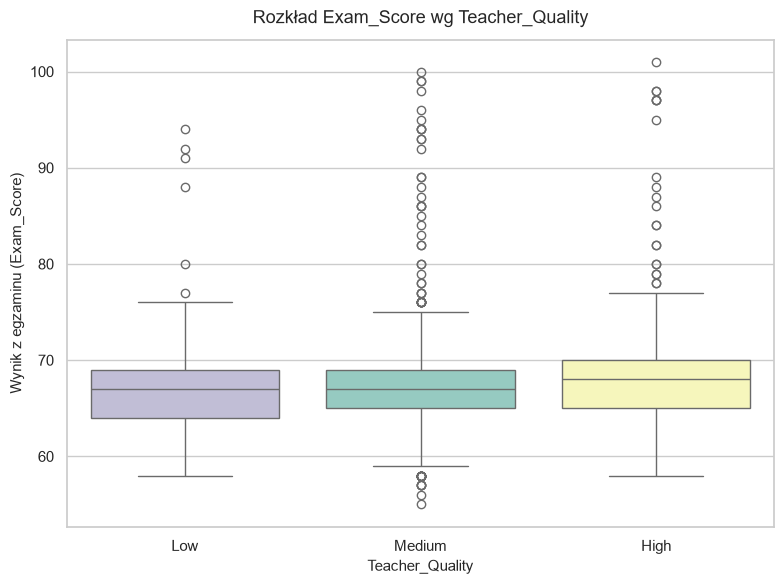


=== MEDIANY Exam_Score wg: Teacher_Quality ===
Teacher_Quality  Mediana_Exam_Score
           High                68.0
            Low                67.0
         Medium                67.0

=== TEST KRUSKALA-WALLISA DLA ZMIENNEJ: Teacher_Quality (Liczebność grup: 3) ===
Grupa "High": n = 1947
Grupa "Low": n = 735
Grupa "Medium": n = 3925

Statystyka H (H-value): 46.0264
p-value: 1.0127e-10
Wynik: Odrzucamy H0. Przynajmniej jedna grupa istotnie różni się od pozostałych pod względem wyników.

=== TEST POST-HOC DUNNA (p-value adjusted: Bonferroni) ===
                High           Low        Medium
High    1.000000e+00  6.326315e-09  1.566841e-07
Low     6.326315e-09  1.000000e+00  2.100286e-02
Medium  1.566841e-07  2.100286e-02  1.000000e+00
Wartości w macierzy mniejsze niż 0.05 oznaczają pary grup, które istotnie się różnią.


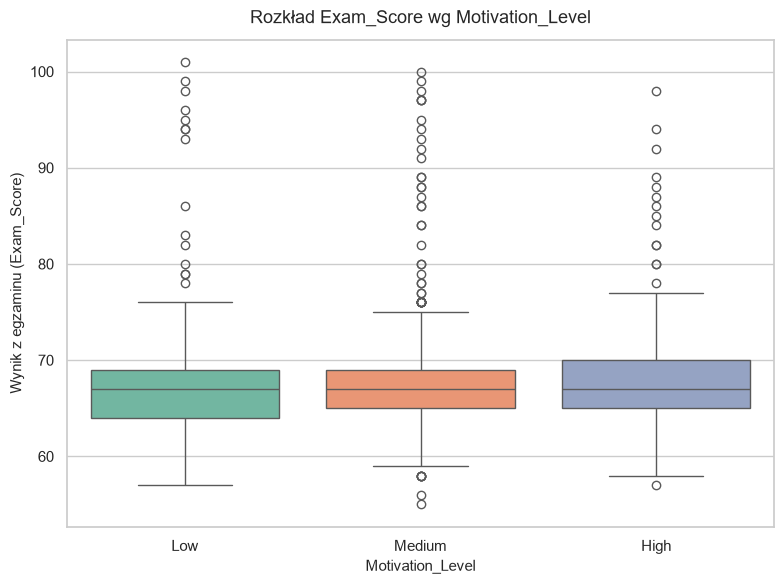


=== MEDIANY Exam_Score wg: Motivation_Level ===
Motivation_Level  Mediana_Exam_Score
            High                67.0
             Low                67.0
          Medium                67.0

=== TEST KRUSKALA-WALLISA DLA ZMIENNEJ: Motivation_Level (Liczebność grup: 3) ===
Grupa "High": n = 1319
Grupa "Low": n = 1937
Grupa "Medium": n = 3351

Statystyka H (H-value): 59.0852
p-value: 1.4784e-13
Wynik: Odrzucamy H0. Przynajmniej jedna grupa istotnie różni się od pozostałych pod względem wyników.

=== TEST POST-HOC DUNNA (p-value adjusted: Bonferroni) ===
                High           Low        Medium
High    1.000000e+00  9.405137e-13  1.073090e-02
Low     9.405137e-13  1.000000e+00  2.010965e-08
Medium  1.073090e-02  2.010965e-08  1.000000e+00
Wartości w macierzy mniejsze niż 0.05 oznaczają pary grup, które istotnie się różnią.


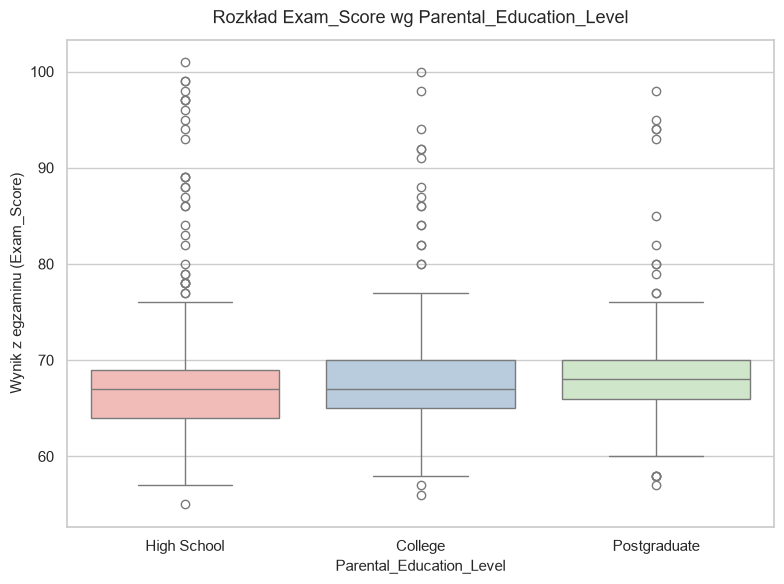


=== MEDIANY Exam_Score wg: Parental_Education_Level ===
Parental_Education_Level  Mediana_Exam_Score
                 College                67.0
             High School                67.0
            Postgraduate                68.0

=== TEST KRUSKALA-WALLISA DLA ZMIENNEJ: Parental_Education_Level (Liczebność grup: 3) ===
Grupa "College": n = 1989
Grupa "High School": n = 3313
Grupa "Postgraduate": n = 1305

Statystyka H (H-value): 93.2412
p-value: 5.6615e-21
Wynik: Odrzucamy H0. Przynajmniej jedna grupa istotnie różni się od pozostałych pod względem wyników.

=== TEST POST-HOC DUNNA (p-value adjusted: Bonferroni) ===
                   College   High School  Postgraduate
College       1.000000e+00  5.246363e-05  2.426301e-07
High School   5.246363e-05  1.000000e+00  3.038909e-21
Postgraduate  2.426301e-07  3.038909e-21  1.000000e+00
Wartości w macierzy mniejsze niż 0.05 oznaczają pary grup, które istotnie się różnią.


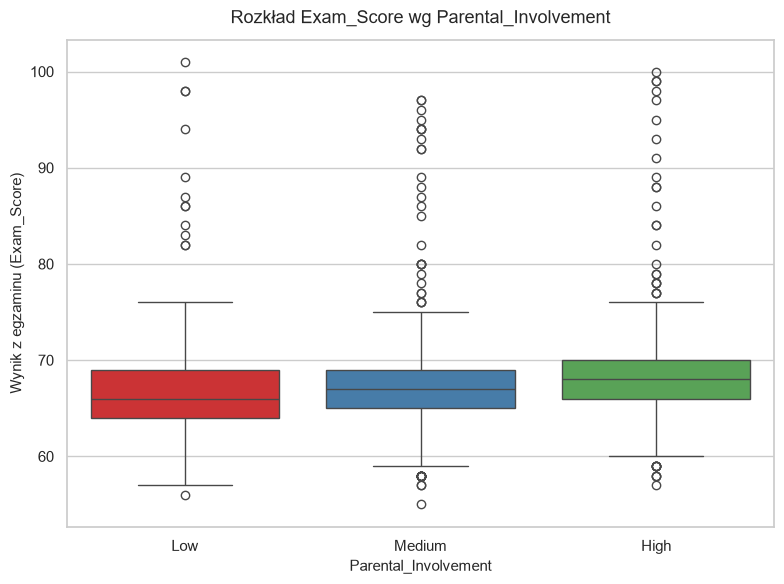


=== MEDIANY Exam_Score wg: Parental_Involvement ===
Parental_Involvement  Mediana_Exam_Score
                High                68.0
                 Low                66.0
              Medium                67.0

=== TEST KRUSKALA-WALLISA DLA ZMIENNEJ: Parental_Involvement (Liczebność grup: 3) ===
Grupa "High": n = 1908
Grupa "Low": n = 1337
Grupa "Medium": n = 3362

Statystyka H (H-value): 195.9245
p-value: 2.8545e-43
Wynik: Odrzucamy H0. Przynajmniej jedna grupa istotnie różni się od pozostałych pod względem wyników.

=== TEST POST-HOC DUNNA (p-value adjusted: Bonferroni) ===
                High           Low        Medium
High    1.000000e+00  1.263241e-42  7.212644e-20
Low     1.263241e-42  1.000000e+00  8.297121e-12
Medium  7.212644e-20  8.297121e-12  1.000000e+00
Wartości w macierzy mniejsze niż 0.05 oznaczają pary grup, które istotnie się różnią.


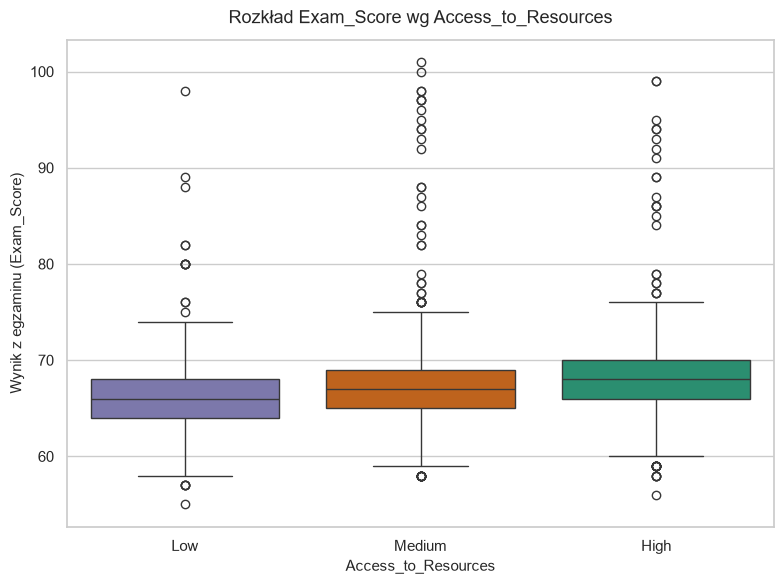


=== MEDIANY Exam_Score wg: Access_to_Resources ===
Access_to_Resources  Mediana_Exam_Score
               High                68.0
                Low                66.0
             Medium                67.0

=== TEST KRUSKALA-WALLISA DLA ZMIENNEJ: Access_to_Resources (Liczebność grup: 3) ===
Grupa "High": n = 1975
Grupa "Low": n = 1313
Grupa "Medium": n = 3319

Statystyka H (H-value): 231.6782
p-value: 4.9171e-51
Wynik: Odrzucamy H0. Przynajmniej jedna grupa istotnie różni się od pozostałych pod względem wyników.

=== TEST POST-HOC DUNNA (p-value adjusted: Bonferroni) ===
                High           Low        Medium
High    1.000000e+00  4.259524e-50  9.155691e-23
Low     4.259524e-50  1.000000e+00  4.830312e-14
Medium  9.155691e-23  4.830312e-14  1.000000e+00
Wartości w macierzy mniejsze niż 0.05 oznaczają pary grup, które istotnie się różnią.


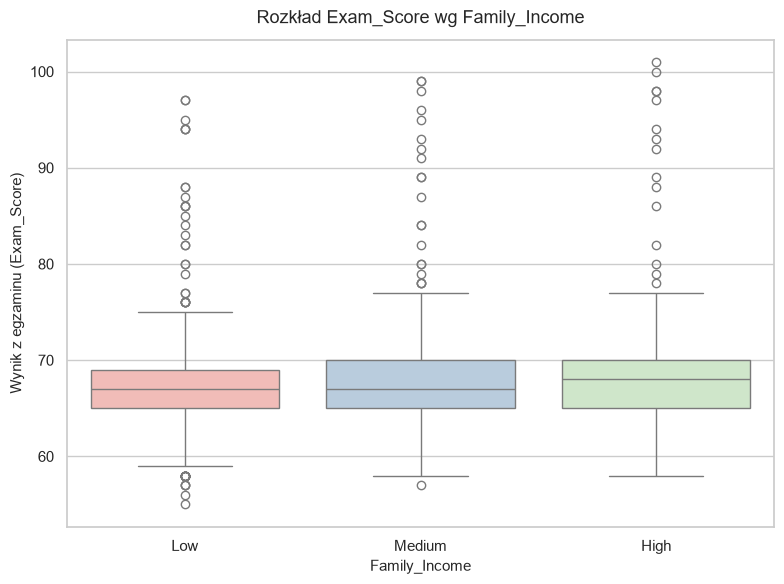


=== MEDIANY Exam_Score wg: Family_Income ===
Family_Income  Mediana_Exam_Score
         High                68.0
          Low                67.0
       Medium                67.0

=== TEST KRUSKALA-WALLISA DLA ZMIENNEJ: Family_Income (Liczebność grup: 3) ===
Grupa "High": n = 1269
Grupa "Low": n = 2672
Grupa "Medium": n = 2666

Statystyka H (H-value): 63.8004
p-value: 1.3994e-14
Wynik: Odrzucamy H0. Przynajmniej jedna grupa istotnie różni się od pozostałych pod względem wyników.

=== TEST POST-HOC DUNNA (p-value adjusted: Bonferroni) ===
                High           Low    Medium
High    1.000000e+00  4.456336e-14  0.000884
Low     4.456336e-14  1.000000e+00  0.000001
Medium  8.840626e-04  1.220268e-06  1.000000
Wartości w macierzy mniejsze niż 0.05 oznaczają pary grup, które istotnie się różnią.


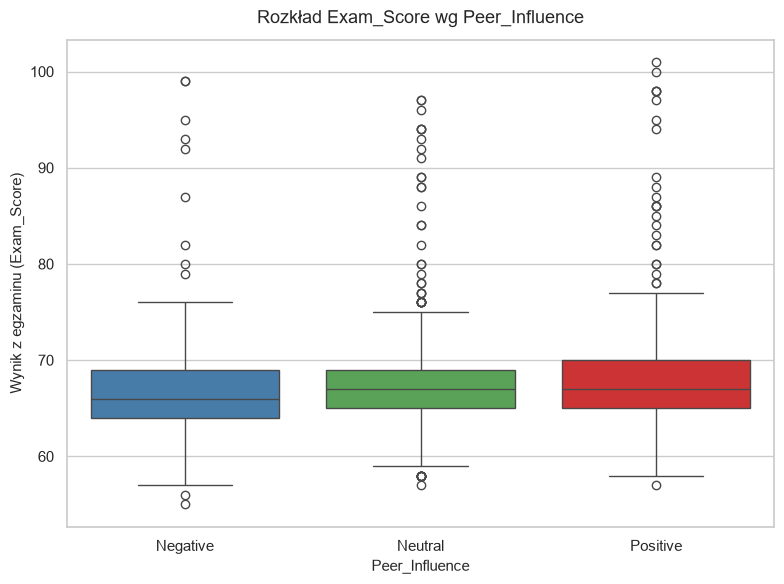


=== MEDIANY Exam_Score wg: Peer_Influence ===
Peer_Influence  Mediana_Exam_Score
      Negative                66.0
       Neutral                67.0
      Positive                67.0

=== TEST KRUSKALA-WALLISA DLA ZMIENNEJ: Peer_Influence (Liczebność grup: 3) ===
Grupa "Negative": n = 1377
Grupa "Neutral": n = 2592
Grupa "Positive": n = 2638

Statystyka H (H-value): 84.9913
p-value: 3.5025e-19
Wynik: Odrzucamy H0. Przynajmniej jedna grupa istotnie różni się od pozostałych pod względem wyników.

=== TEST POST-HOC DUNNA (p-value adjusted: Bonferroni) ===
              Negative       Neutral      Positive
Negative  1.000000e+00  1.522661e-07  1.198919e-19
Neutral   1.522661e-07  1.000000e+00  2.288244e-05
Positive  1.198919e-19  2.288244e-05  1.000000e+00
Wartości w macierzy mniejsze niż 0.05 oznaczają pary grup, które istotnie się różnią.


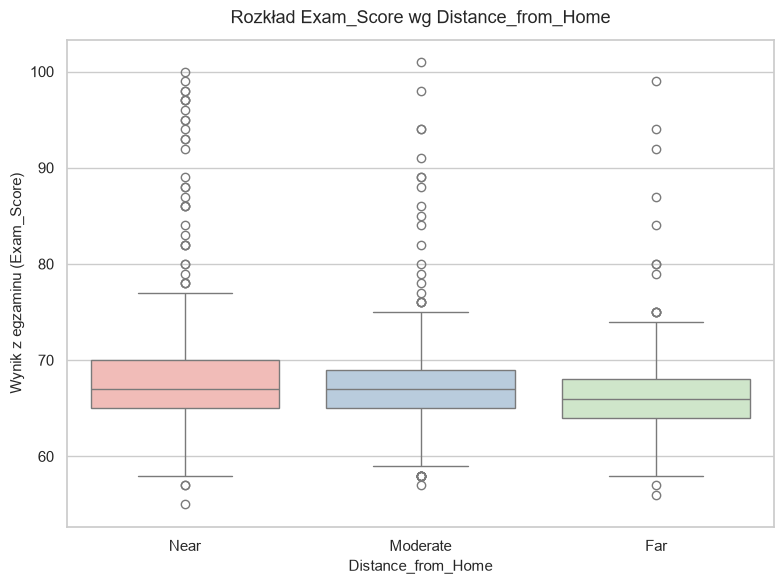


=== MEDIANY Exam_Score wg: Distance_from_Home ===
Distance_from_Home  Mediana_Exam_Score
               Far                66.0
          Moderate                67.0
              Near                67.0

=== TEST KRUSKALA-WALLISA DLA ZMIENNEJ: Distance_from_Home (Liczebność grup: 3) ===
Grupa "Far": n = 658
Grupa "Moderate": n = 2065
Grupa "Near": n = 3884

Statystyka H (H-value): 71.6046
p-value: 2.8266e-16
Wynik: Odrzucamy H0. Przynajmniej jedna grupa istotnie różni się od pozostałych pod względem wyników.

=== TEST POST-HOC DUNNA (p-value adjusted: Bonferroni) ===
                   Far      Moderate          Near
Far       1.000000e+00  1.130035e-03  3.621234e-13
Moderate  1.130035e-03  1.000000e+00  5.268227e-08
Near      3.621234e-13  5.268227e-08  1.000000e+00
Wartości w macierzy mniejsze niż 0.05 oznaczają pary grup, które istotnie się różnią.


In [29]:
kruskal_wallis(
    df,
    group_col='Teacher_Quality',
    target_col='Exam_Score',
    palette='Set3',
    order=['Low', 'Medium', 'High'],
)

kruskal_wallis(
    df,
    group_col='Motivation_Level',
    target_col='Exam_Score',
    palette='Set2',
    order=['Low', 'Medium', 'High'],
)

kruskal_wallis(
    df,
    group_col='Parental_Education_Level',
    target_col='Exam_Score',
    palette='Pastel1',
    order=['High School', 'College', 'Postgraduate'],
)

kruskal_wallis(
    df,
    group_col='Parental_Involvement',
    target_col='Exam_Score',
    palette='Set1',
    order=['Low', 'Medium', 'High'],
)

kruskal_wallis(
    df,
    group_col='Access_to_Resources',
    target_col='Exam_Score',
    palette='Dark2',
    order=['Low', 'Medium', 'High'],
)

kruskal_wallis(
    df,
    group_col='Family_Income',
    target_col='Exam_Score',
    palette='Pastel1',
    order=['Low', 'Medium', 'High'],
)

kruskal_wallis(
    df,
    group_col='Peer_Influence',
    target_col='Exam_Score',
    palette='Set1',
    order=['Negative', 'Neutral', 'Positive'],
)

kruskal_wallis(
    df,
    group_col='Distance_from_Home',
    target_col='Exam_Score',
    palette='Pastel1',
    order=['Near', 'Moderate', 'Far'],
)

Nieparametryczny test **Kruskala-Wallisa** wykazał istotne różnice między grupami dla wszystkich zmiennych (`Teacher_Quality`, `Motivation_Level`, `Parental_Education_Level`, `Parental_Involvement`, `Access_to_Resources`, `Family_Income`, `Peer_Influence`, `Distance_from_Home`). Podobnie jak w przypadku testa U Manna-Whitneya należy pamiętać o **dużym rozmiarze próby (n = 6 607)**, przez który test staje się bardzo czuły. Wartości mediany dla wszystkich grup są zbliżone do 67, a wykresy *box-plot* nie wskazują na duże róznice w rozkładzie. Mimo to, warto przeanalizować widoczne na nich **wartości odstające**.

* Test Kruskala-Wallisa wykazuje statystyczną istotność wpływu **jakości nauczania (`Teacher_Quality`) na wyniki egzaminu (`Exam_Score`)**. Według testu *post-hoc* Dunna z poprawką Bonferroniego wszystkie grupy różnią się między sobą. Na wykresach *box-plot* widać, że rozkłady mimo to pozostają do siebie podobne. Najważniejszą różnicą jest większa liczba skrajnych wyników w grupie `Medium` i `High` w porównaniu do grupy `Low`. Można wnioskować, że **osoby z grupy o najniższej jakości nauczania rzadziej otrzymują tak wysokie wyniki jak pozostałe grupy**.
* Test wskazuje że wyniki egzaminu **są zróżnicowane według poziomu motywacji (`Motivation_Level`)**, a nawet że wszystkie grupy różnią się istotnie między sobą. Mimo to, analiza median i wykresów *box-plot* przynosi podobne wnioski jak w przypadku jakości nauczania.
* Podobne wnioski niesie ze sobą wnikliwa analiza testów i wykresów przeprowadzonych dla `Parental_Education_Level`, `Parental_Involvement`, `Family_Income`, `Peer_Influence`.
* Grupy według dostępu do zasobów (`Access_to_Resources`) teoretycznie istotnie różnią się między sobą ze względu na wyniki egzaminu, jednak przebiega to analogicznie jak dla wcześniejszych zmiennych. Ciekawą obserwacją jest mniejsza liczba wartości odstających dla grupy `Low` niż dla `Medium` i `High`, co pociąga za sobą wniosek, że **uczniowie o niskim poziomie dostępu do zasobów nauczania rzadziej osiągają skrajnie wysokie oceny niż grupy o średnim i wysokim dostępie.**
* W przypadku odległości od domu (`Distance_from_Home`) najwięcej wartości ekstremalnych zauważyć można dla grup `Near` i `Moderate`, podczas gdy grupa `Far` ma ich mniej. Sugeruje to, że **uczniowie o niedużym dystansie od domu częściej otrzymują najwyższe wyniki z egzaminu niż uczniowie, u których ten dystans jest duży.**

### 3.3. Analiza korelacji

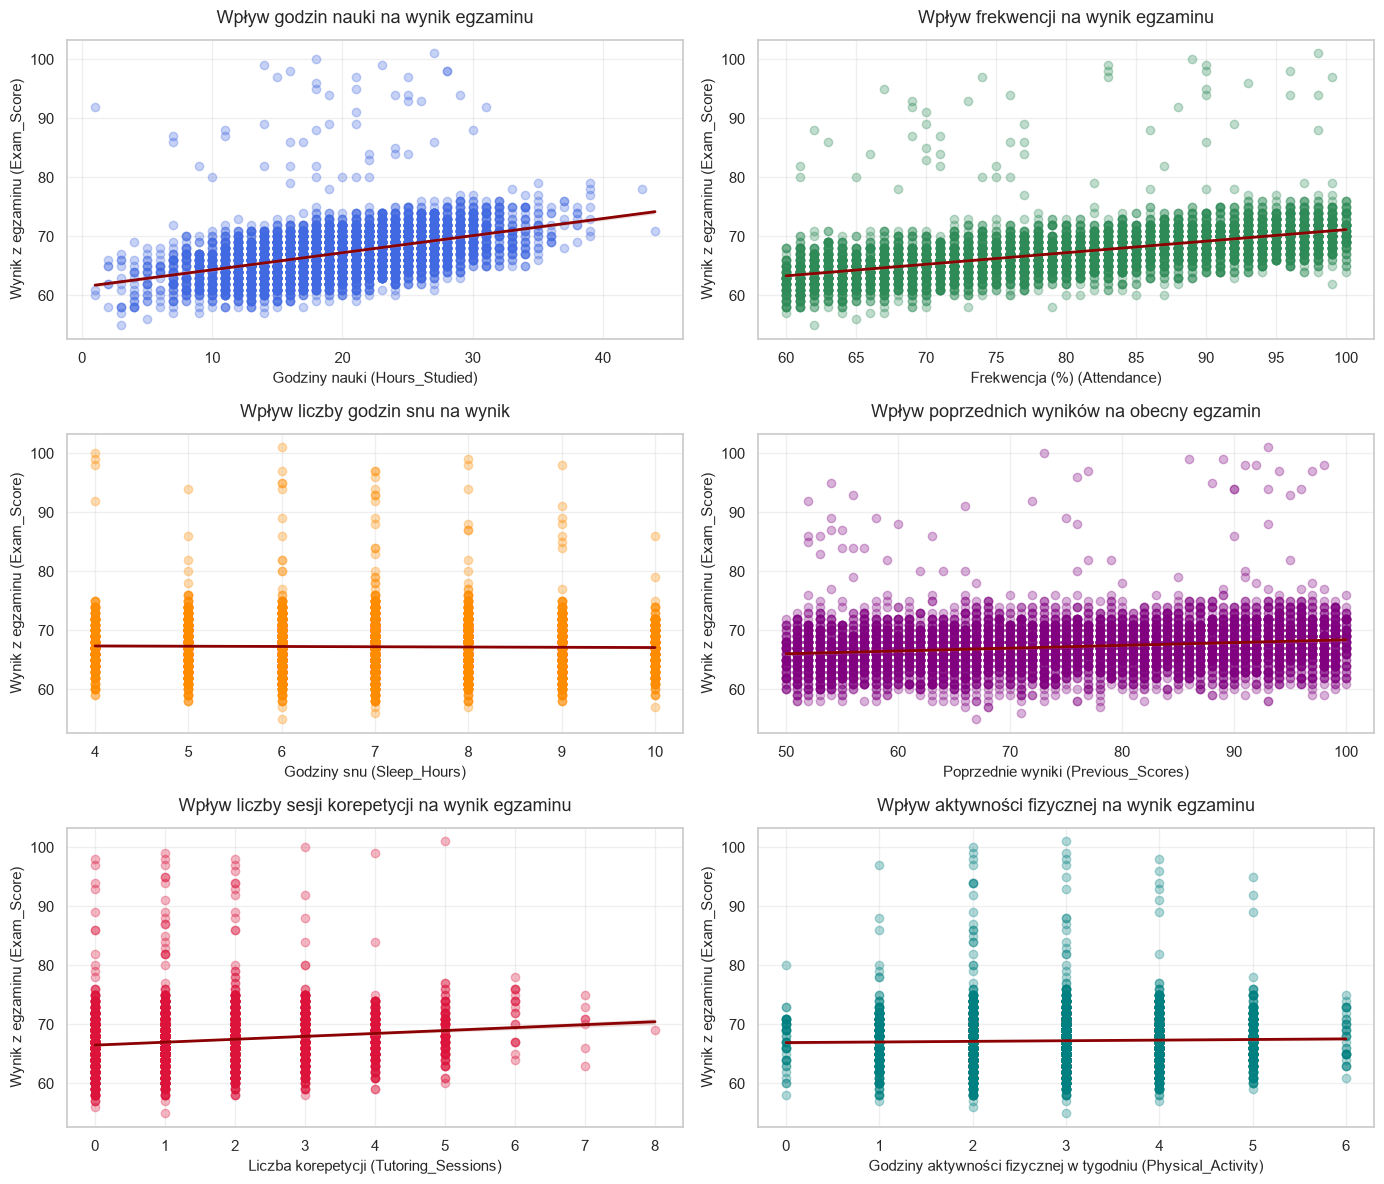

=== ANALIZA KORELACJI: Hours_Studied vs Exam_Score ===
Liczebność par (n): 6607
Korelacja Spearmana (rho): 0.4810 | p-value: 0.0000e+00
Korelacja Pearsona (r):    0.4455 | p-value: 1.2863e-319

Wynik: Istnieje statystycznie istotna zależność (dodatnia). 

=== ANALIZA KORELACJI: Attendance vs Exam_Score ===
Liczebność par (n): 6607
Korelacja Spearmana (rho): 0.6724 | p-value: 0.0000e+00
Korelacja Pearsona (r):    0.5811 | p-value: 0.0000e+00

Wynik: Istnieje statystycznie istotna zależność (dodatnia). 

=== ANALIZA KORELACJI: Sleep_Hours vs Exam_Score ===
Liczebność par (n): 6607
Korelacja Spearmana (rho): -0.0076 | p-value: 5.3527e-01
Korelacja Pearsona (r):    -0.0170 | p-value: 1.6654e-01

Wynik: Brak istotnej zależności statystycznej między zmiennymi. 

=== ANALIZA KORELACJI: Previous_Scores vs Exam_Score ===
Liczebność par (n): 6607
Korelacja Spearmana (rho): 0.1919 | p-value: 7.4030e-56
Korelacja Pearsona (r):    0.1751 | p-value: 1.2444e-46

Wynik: Istnieje statystycznie istotna 

In [31]:
tytuly = [
    'Wpływ godzin nauki na wynik egzaminu',
    'Wpływ frekwencji na wynik egzaminu',
    'Wpływ liczby godzin snu na wynik',
    'Wpływ poprzednich wyników na obecny egzamin',
    'Wpływ liczby sesji korepetycji na wynik egzaminu',
    'Wpływ aktywności fizycznej na wynik egzaminu',
]

etykiety = [
    'Godziny nauki (Hours_Studied)',
    'Frekwencja (%) (Attendance)',
    'Godziny snu (Sleep_Hours)',
    'Poprzednie wyniki (Previous_Scores)',
    'Liczba korepetycji (Tutoring_Sessions)',
    'Godziny aktywności fizycznej w tygodniu (Physical_Activity)',
]

kolory = ['royalblue', 'seagreen', 'darkorange', 'purple', 'crimson', 'teal']

fig, axes = plt.subplots(3, 2, figsize=(14, 12))
axes_flat = axes.flatten()

for i, col in enumerate(X_numeryczne):
    ax = axes_flat[i]  

    sns.regplot(
        data=dane,
        x=col,
        y='Exam_Score',
        ax=ax,
        scatter_kws={'alpha': 0.3, 'color': kolory[i]},  
        line_kws={'color': 'darkred', 'linewidth': 2},
    )

    ax.set_title(tytuly[i], fontsize=13, pad=12)
    ax.set_xlabel(etykiety[i], fontsize=11)
    ax.set_ylabel('Wynik z egzaminu (Exam_Score)', fontsize=11)
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

korelacja(df, x='Hours_Studied')
korelacja(df, x='Attendance')
korelacja(df, x='Sleep_Hours')
korelacja(df, x = 'Previous_Scores')
korelacja(df, x = 'Tutoring_Sessions')
korelacja(df, x = 'Physical_Activity')

**Wszystkie analizowane istotne zależności są dodatnie.** Test Spearmana jako jedyną zmienną niepowiązaną z wynikiem egzaminu wskazał liczbę przespanych godzin (`Sleep_Hours`).

* Największą korelację z wynikiem egzaminu wykazują obecność (`Attendace`, *rho* = 0,67) i godziny poświęcone na naukę (`Hours_Studied`, *rho* = 0,48). Wyniki te znajdują potwierdzenie na wykresach zależności.
* Umiarkowaną zależność z wynikiem egzaminu wykazują poprzednie wyniki (`Previous_Scores`, *rho* = 0,19) i liczba sesji korepetycji (`Tutoring_Sessions`, *rho* = 0,16).
* Znikoma korelacja została zaobserwowana między wynikiem egzaminu a aktywnością fizyczną (`Physical_Activity`, *rho* = 0,03).



## 4. Modelowanie predykcyjne 

### 4.1. Kodowanie zmiennych oraz podział na zbiór treningowy i testowy

In [47]:
#istotne zmienne
istotne = X.drop(columns=['Sleep_Hours', 'Gender', 'School_Type'])

#kodowanie kategorycznych zmiennych
X_zakodowane = pd.get_dummies(istotne, drop_first=True)

#80%/20% split
X_train, X_test, y_train, y_test = train_test_split(
    X_zakodowane, y, test_size=0.2, random_state=69
)

### 4.2. Regresja liniowa jako baseline

In [48]:
#model bazowy (regresja liniowa)
baseline_model = LinearRegression()
baseline_model.fit(X_train, y_train)

#predykcja i ewaluacja
y_pred = baseline_model.predict(X_test)

In [49]:
#model liniowy ze stałą dla sprawdzenia istotności zmiennych
X_train_sm = sm.add_constant(X_train)
X_test_sm = sm.add_constant(X_test)

ols_model = sm.OLS(y_train, X_train_sm)
ols_results = ols_model.fit()

print(ols_results.summary())

                            OLS Regression Results                            
Dep. Variable:             Exam_Score   R-squared:                       0.735
Model:                            OLS   Adj. R-squared:                  0.734
Method:                 Least Squares   F-statistic:                     609.1
Date:                Fri, 13 Nov 2026   Prob (F-statistic):               0.00
Time:                        13:42:36   Log-Likelihood:                -11078.
No. Observations:                5285   AIC:                         2.221e+04
Df Residuals:                    5260   BIC:                         2.237e+04
Df Model:                          24                                         
Covariance Type:            nonrobust                                         
                                            coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------------------------

**Wszystkie zmienne są istotne statystycznie (p-value = 0,000).**

### 4.3. Random Forest

In [50]:
#random forest
rf_model = RandomForestRegressor(
    n_estimators=100, max_depth=15, random_state=69, n_jobs=-1)
rf_model.fit(X_train, y_train)
y_pred_rf = rf_model.predict(X_test)

### 4.4. Gradient Boosting

In [51]:
#gradient boosting
gb_model = GradientBoostingRegressor(
    n_estimators=100, learning_rate=0.1, max_depth=5, random_state=69)
gb_model.fit(X_train, y_train)
y_pred_gb = gb_model.predict(X_test)

### 4.5. Ewaluacja wyników

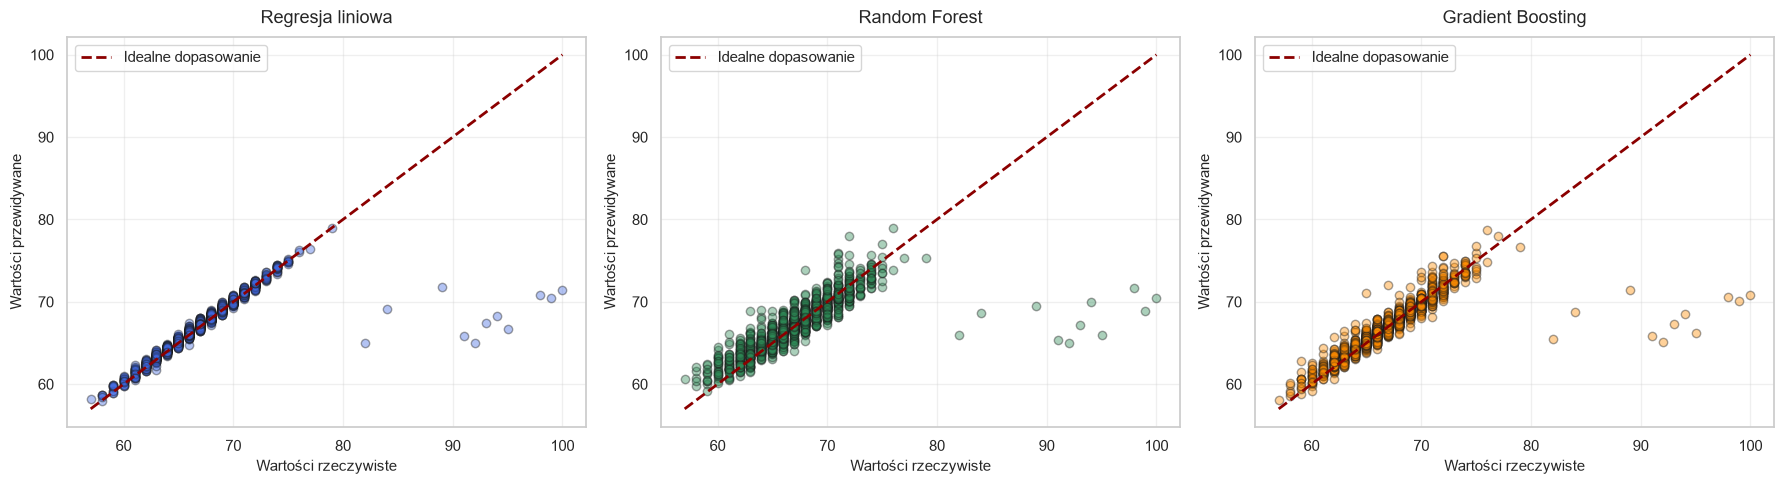

=== Regresja Liniowa (baseline) ===
R^2 (Współczynnik determinacji): 0.6952
RMSE (Błąd średniokwadratowy): 2.2804
MAE (Średni błąd bezwzględny): 0.5218

=== Random Forest ===
R^2 (Współczynnik determinacji): 0.5945
RMSE (Błąd średniokwadratowy): 2.6305
MAE (Średni błąd bezwzględny): 1.2119

=== Gradient Boosting ===
R^2 (Współczynnik determinacji): 0.6565
RMSE (Błąd średniokwadratowy): 2.4209
MAE (Średni błąd bezwzględny): 0.8472



In [52]:
nazwy_modeli = ['Regresja liniowa', 'Random Forest', 'Gradient Boosting']
predykcje = [y_pred, y_pred_rf, y_pred_gb]
kolory = ['royalblue', 'seagreen', 'darkorange']

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, ax in enumerate(axes):
    ax.scatter(y_test, predykcje[i], alpha=0.4, color=kolory[i], edgecolors='k')
    
    min_val = min(min(y_test), min(predykcje[i]))
    max_val = max(max(y_test), max(predykcje[i]))
    ax.plot([min_val, max_val], [min_val, max_val], color='darkred', lw=2, linestyle='--', label='Idealne dopasowanie')
    
    ax.set_title(f'{nazwy_modeli[i]}', fontsize=13, pad=10)
    ax.set_xlabel('Wartości rzeczywiste', fontsize=11)
    ax.set_ylabel('Wartości przewidywane', fontsize=11)
    ax.grid(True, alpha=0.3)
    ax.legend(loc='upper left')

plt.tight_layout()
plt.show()

#funkcja pomocnicza
def evaluate_model(name, y_true, y_pred):
  r2 = r2_score(y_true, y_pred)
  rmse = np.sqrt(mean_squared_error(y_true, y_pred))
  mae = mean_absolute_error(y_true, y_pred)

  print(f'=== {name} ===')
  print(f'R^2 (Współczynnik determinacji): {r2:.4f}')
  print(f'RMSE (Błąd średniokwadratowy): {rmse:.4f}')
  print(f'MAE (Średni błąd bezwzględny): {mae:.4f}\n')


#ewaluacja wszystkich modeli
evaluate_model('Regresja Liniowa (baseline)', y_test, y_pred)
evaluate_model('Random Forest', y_test, y_pred_rf)
evaluate_model('Gradient Boosting', y_test, y_pred_gb)

Najlepsze wyniki według wszystkich kryteriów osiąga model bazowy, czyli **regresja liniowa.** Zdobywa **najwyższy współczynnik determinacji** `R2` (0,7697 vs 0,6555 vs 0,7186) oraz **najniższy błąd średniokwadratowy `RMSE`** (1,8043 vs 2,2069 vs 1,9944) i **najniższy średni błąd bezwględny `MAE`** (0,4495 vs 1,1485 vs 0,7731). 

* Wyższość regresji liniowej nad modelami opartymi na drzewach decyzyjnych (Random Forest, Gradient Boosting) potwierdza, że relacje pomiędzy zmiennymi objaśniającymi a wynikiem egzaminu mają **charakter silnie liniowy**. W tym przypadku złożone algorytmy nieliniowe miały tendencję do nadmiernego dopasowania (*overfittingu*) na zbiorze treningowym.
* Analiza wizualna wykresów ujawnia powtarzalny wzorzec dla wszystkich trzech modeli, jakim jest **wyraźne niedoszacowanie wyników w prawym górnym rogu** (dla uczniów ze skrajnie wysokimi wynikami powyżej 80-90 punktów). Oznacza to, że żaden z modeli nie uchwycił w pełni specyfiki nieliniowego „sufitu” dla najlepszych osiągnięć.

Regresja liniowa nie tylko generuje najniższe błędy predykcji, ale oferuje też **pełną interpretowalność współczynników**, co czyni ją optymalnym wyborem biznesowym i badawczym.

### 4.6. Hiperparametry dla Gradient Boosting

In [53]:
#przestrzeń hiperparametrów
param_distributions_gb = {
    'n_estimators': [100, 200, 300, 500],
    'learning_rate': [0.01, 0.05, 0.1, 0.2],
    'max_depth': [3, 4, 5, 7],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'subsample': [0.8, 0.9, 1.0]  
}

#bazowy model
gb = GradientBoostingRegressor(random_state=69)

#konfiguracja
random_search_gb = RandomizedSearchCV(
    estimator=gb,
    param_distributions=param_distributions_gb,
    n_iter=15,          
    cv=3,             
    scoring='r2',       
    random_state=69,
    n_jobs=-1,
    verbose=2
)

print("Rozpoczęto strojenie hiperparametrów dla Gradient Boosting...")
random_search_gb.fit(X_train, y_train)

#wyniki
print("\nNajlepsze znalezione parametry dla GB:")
print(random_search_gb.best_params_)

best_gb = random_search_gb.best_estimator_

#predykcja i ewaluacja na zbiorze testowym
y_pred_tuned_gb = best_gb.predict(X_test)

r2_tuned_gb = r2_score(y_test, y_pred_tuned_gb)
rmse_tuned_gb = np.sqrt(mean_squared_error(y_test, y_pred_tuned_gb))
mae_tuned_gb = mean_absolute_error(y_test, y_pred_tuned_gb)

print("\n=== WYNIKI STROJONEGO GRADIENT BOOSTING ===")
print(f"R^2 (Współczynnik determinacji): {r2_tuned_gb:.4f}")
print(f"RMSE (Błąd średniokwadratowy): {rmse_tuned_gb:.4f}")
print(f"MAE (Średni błąd bezwzględny): {mae_tuned_gb:.4f}")

Rozpoczęto strojenie hiperparametrów dla Gradient Boosting...
Fitting 3 folds for each of 15 candidates, totalling 45 fits

Najlepsze znalezione parametry dla GB:
{'subsample': 0.9, 'n_estimators': 300, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_depth': 3, 'learning_rate': 0.05}

=== WYNIKI STROJONEGO GRADIENT BOOSTING ===
R^2 (Współczynnik determinacji): 0.6711
RMSE (Błąd średniokwadratowy): 2.3690
MAE (Średni błąd bezwzględny): 0.7625


Dodatkowo, mimo próby dostrojenia hiperparametrów dla drugiego najlepszego modelu (Gradient Boosting), jego **wyniki nadal pozostały gorsze niż wyniki dla regresji liniowej** (`R2`: 0,6711 vs 0,6952, `RMSE`: 2,3690 vs 2,2804, `MSE`: 0,7625 vs 0,5218).

### 4.7. Regresja liniowa jako model finalny

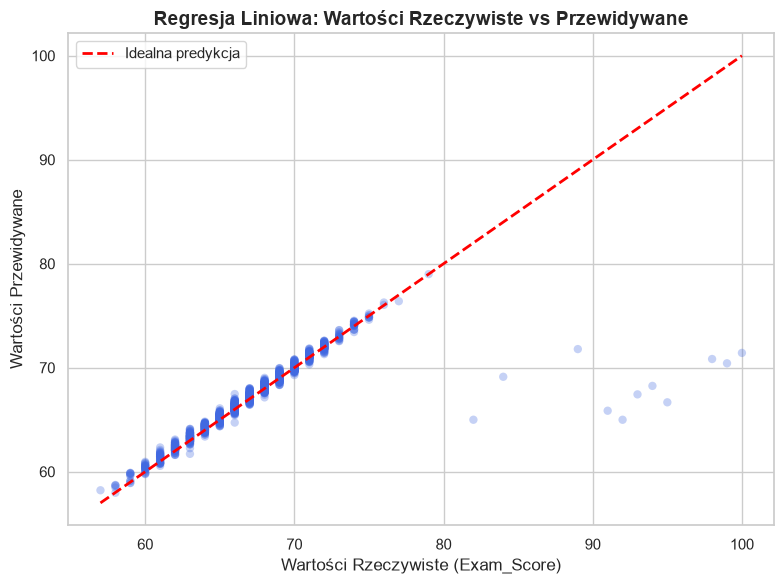

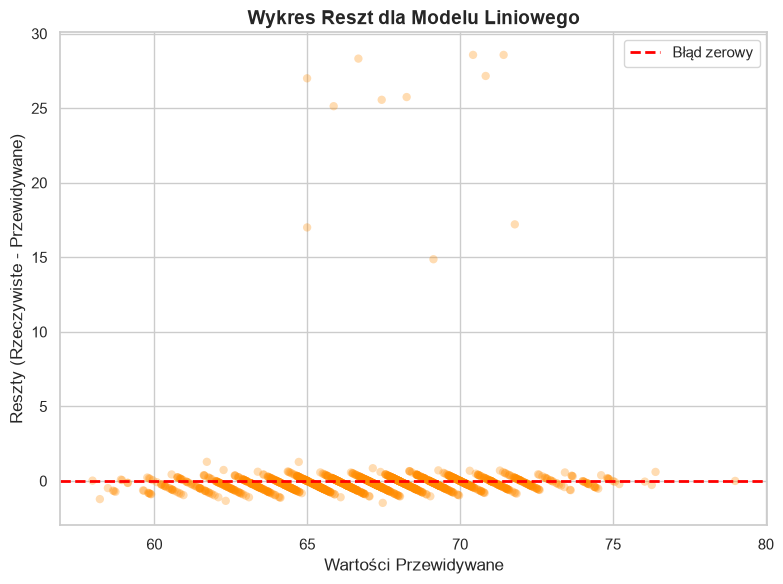

In [54]:
sns.set_theme(style="whitegrid")

#wykres rzeczywiste vs prognozowane
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, alpha=0.3, color='royalblue', edgecolors='none')

min_val = min(y_test.min(), y_pred.min())
max_val = max(y_test.max(), y_pred.max())
plt.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--', linewidth=2, label='Idealna predykcja')

plt.title('Regresja Liniowa: Wartości Rzeczywiste vs Przewidywane', fontsize=14, fontweight='bold')
plt.xlabel('Wartości Rzeczywiste (Exam_Score)', fontsize=12)
plt.ylabel('Wartości Przewidywane', fontsize=12)
plt.legend()
plt.tight_layout()
plt.show()

#wykres reszt
residuals = y_test - y_pred

plt.figure(figsize=(8, 6))
plt.scatter(y_pred, residuals, alpha=0.3, color='darkorange', edgecolors='none')
plt.axhline(y=0, color='red', linestyle='--', linewidth=2, label='Błąd zerowy')

plt.title('Wykres Reszt dla Modelu Liniowego', fontsize=14, fontweight='bold')
plt.xlabel('Wartości Przewidywane', fontsize=12)
plt.ylabel('Reszty (Rzeczywiste - Przewidywane)', fontsize=12)
plt.legend()
plt.tight_layout()
plt.show()

Zdecydowana większość punktów układa się w zwartą, diagonalną linię idealnie pokrywającą się z czerwoną linią przerywaną (reprezentującą idealną predykcję) w przedziale od ok. 55 do 75 punktów. Dowodzi to, że model liniowy znakomicie odwzorowuje relacje dla przeciętnych wyników z egzaminu. W prawym dolnym rogu widoczne są nieliczne punkty odstające (uczniowie, których rzeczywisty wynik wynosił 80-98 punktów). Model przewiduje dla nich znacznie niższe wartości (w przedziale 60-75). Oznacza to, że model liniowy napotyka na ograniczenie strukturalne w górnym zakresie skali, systematycznie niedoszacowując osiągnięcia najlepszych uczniów.

Model oparty na regresji liniowej charakteryzuje się wysoką stabilnością i precyzją dla typowych uczniów, co tłumaczy jego wysoki współczynnik determinacji. Jego głównym ograniczeniem jest jednak niezdolność do uchwycenia nieliniowego „skoku” w górnym przedziale skali ocen, co stanowi cenny wniosek analityczny odnośnie specyfiki badanego zbioru danych.

In [55]:
evaluate_model('Regresja Liniowa (baseline)', y_test, y_pred)

wspolczynniki = pd.DataFrame(
    {'Cecha': X_train.columns, 'Waga (Wpływ na wynik)': baseline_model.coef_})

wspolczynniki = wspolczynniki.sort_values(
    by='Waga (Wpływ na wynik)', ascending=False)

print('Współczynniki w modelu liniowym:')
print(wspolczynniki.to_string(index=False))

=== Regresja Liniowa (baseline) ===
R^2 (Współczynnik determinacji): 0.6952
RMSE (Błąd średniokwadratowy): 2.2804
MAE (Średni błąd bezwzględny): 0.5218

Współczynniki w modelu liniowym:
                                Cecha  Waga (Wpływ na wynik)
              Peer_Influence_Positive               1.054553
                  Internet_Access_Yes               0.941076
              Distance_from_Home_Near               0.887960
               Peer_Influence_Neutral               0.570760
Parental_Education_Level_Postgraduate               0.558523
       Extracurricular_Activities_Yes               0.533906
                    Tutoring_Sessions               0.493638
          Distance_from_Home_Moderate               0.342247
                        Hours_Studied               0.295423
                           Attendance               0.197599
                    Physical_Activity               0.177870
                      Previous_Scores               0.046964
 Parental_Education_L

Największy pozytywny wpływ na wyniki egzaminu ma **pozytywny wpływ rówieśników na naukę, dostęp do internetu i mały dystans do domu.**
* Uczniowie, którzy określają wpływ swoich rówieśników jako pozytywny osiągają średnio o 1,1 punktu z egzaminu więcej niż uczniowie, którzy określają go jako negatywny, przy założeniu *ceteris paribus*.
* Osoby z dostępem do internetu mają średnio o 0,9 punktu wyższe wyniki z egzaminu niż osoby bez dostępu do internetu, przy założeniu *ceteris paribus*.
* Uczniowie, którzy przemierzają mały dystans między szkołą a domem uzyskują średnio o 0,9 więcej punkta z egzaminu niż uczniowie, którzy muszą przebyć dużą odległość, przy założeniu *ceteris paribus*.

Największy negatywny wpływ na wyniki egzaminu ma **niski poziom dostępu do zasobów edukacyjnych, niski poziom zaangażowania rodziców w naukę ucznia, pochodzenie z rodziny o niskim dochodzie oraz niski poziom motywacji.**
* Osoby o małym dostępie do odpowiednich materiałów naukowych mają średnio o 2 punkty niższe wyniki z egzaminu niż osoby o dużym dostępie do takowych zasobów, przy założeniu *ceteris paribus*.
* Uczniowie o niskim poziomie zaangażowania rodziców w ich edukację osiągają średnio o 1,9 punktu mniej z egzaminu niż osoby, których rodzice wykazują duże zaangażowanie w ich naukę, przy założeniu *ceteris paribus*.
* Niezmotywowani do nauki uczniowie zdobywają średnio o 1,1 punktu mniej z egzaminu niż ci zmotywowani, przy założeniu *ceteris paribus*.

**Najmniejszy wpływ na wynik mają poprzednie wyniki, aktywność fizyczna i frekwencja.**

## 5. Podsumowanie

* Na wyniki egzaminu **nie wpływa płeć, rodzaj szkoły ani liczba godzin snu.**
* Największy wpływ na wyniki egzaminu ma **dostęp do zasobów edukacyjnych, wsparcie rodziców, poziom motywacji, dostęp do internetu i wpływ rówieśników.**
* Zależności w badanej próbie są silnie **liniowe**.
* Modele wykazują systematyczne niedoszacowanie wyników w grupie skrajnie wysokich wyników.